<a href="https://colab.research.google.com/github/fxrdhan/ML_scikit-learn_Cookbook_O-Reilly/blob/main/Chapter_10_Clustering_Techniques/Chapter_10_Clustering_Techniques.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 10 — Clustering Techniques

| | |
|---|---|
| **Book** | *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing, 2025) |
| **Library version targeted by the book** | scikit-learn 1.5 |
| **Version used to run this notebook** | scikit-learn 1.9.1 on Python 3.12 (printed by the setup cell) |
| **What this notebook contains** | reproduction of every code listing in the chapter and of the official exercise solutions, chapter and recipe summaries, theoretical deep-dives, and extra experiments |

## Chapter overview

Up to now every model had a target to predict. Chapter 10 turns to **unsupervised learning**: the data has no labels, and the goal is to find structure in it. **Clustering** groups the samples so that members of a group are more alike than members of different groups. The chapter shows how to:

* group data with **K-means**, and choose the number of clusters with the **elbow method**;
* build a tree of nested clusters with **hierarchical (agglomerative) clustering** and read a **dendrogram**;
* find clusters of any shape, and noise, with **DBSCAN**;
* judge a clustering with the **silhouette score**, the **Davies-Bouldin index** and the **adjusted Rand index**;
* **choose** an algorithm from the shape, noise level, size and dimension of the data;
* use **spectral clustering** and **Gaussian mixture models (GMMs)**;
* practise with three exercises on the Iris, moons and Wine data.

### Recipes in this chapter

| # | Recipe | Code in the book | What this notebook adds |
|---|---|---|---|
| 1 | Introduction to clustering | Yes, 2 listings | The true geometry of the blobs, why scaling matters, and clusters found in pure noise |
| 2 | K-means clustering | Yes, 2 listings | Lloyd's algorithm by hand, the initialization lottery, the elbow against the silhouette, where K-means breaks |
| 3 | Hierarchical clustering | Yes, 1 listing | Ward's method by hand, reading the merge heights, four linkages on three shapes, bisecting K-means |
| 4 | Density-based clustering with DBSCAN | Yes, 2 listings | Core, border and noise points, the k-distance plot decoded, the narrow window of `eps`, varying density |
| 5 | Cluster evaluation metrics | Yes, 1 listing | The three metrics by hand, metrics against the number of clusters, internal metrics on curved clusters, chance correction |
| 6 | Choosing the right clustering algorithm | Yes, 2 listings | Six algorithms on the three shapes, run time against the number of samples, irrelevant features |
| 7 | Advanced clustering techniques | Yes, 2 listings | Spectral clustering by hand, the affinity graph, EM by hand, BIC, soft assignments |
| 8 | Practical exercises with clustering models | Official solutions | The silhouette against the species, the window of `eps`, PCA and GMM on Wine |

### How to read this notebook

Every recipe has the same structure:

1. **Summary** — what the book says, condensed.
2. **Theory** — the ideas behind it: math, algorithms and design reasoning.
3. **Book code** — the listing reproduced from the book (page numbers refer to the printed edition), followed by an **output analysis**.
4. **Extra** — experiments written for this notebook to make the theory concrete. They are *not* part of the book.

Every code cell starts with a label comment: `# BOOK CODE` for a listing reproduced from the book, `# EXTRA` for code written for this notebook.

---
## 0. Setup

Every dataset in this chapter is generated by scikit-learn (`make_blobs`, `make_moons`, `make_circles`) or ships with it (`load_iris`, `load_wine`), so the notebook runs offline. The setup cell prints the library versions, fixes a global seed (every listing also sets `random_state=2024`), and defines the plotting style of the extra figures. Clusters are drawn with a **colour and a marker shape** (circle, square, triangle, ...), so that they stay distinguishable without colour; points labelled as noise are grey crosses. The full notebook runs in about a minute.

In [1]:
import platform
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn

print(f"Python       : {platform.python_version()}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

sk_version = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
assert sk_version >= (1, 5), "This notebook needs scikit-learn >= 1.5 -> pip install -U scikit-learn"

np.random.seed(0)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# scikit-learn warns when a neighbour graph is disconnected (harmless for well-separated clusters); recipe 7 counts those warnings
warnings.filterwarnings("ignore", message="Graph is not fully connected")
# print warnings without the file path, so that the saved output does not depend on the machine
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

# A quiet, colour-blind-safe style used by the extra figures in this notebook
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

MARKERS = ["o", "s", "^", "D", "v", "P"]


def scatter_clusters(ax, X, labels, title=None, size=22, centers=None):
    """Scatter plot with one colour and one marker per cluster; the label -1 (noise) is drawn as grey crosses."""
    labels = np.asarray(labels)
    for label in sorted(set(labels.tolist())):
        mask = labels == label
        if label == -1:
            ax.scatter(X[mask, 0], X[mask, 1], c=MUTED, marker="x", s=size * 1.6, linewidths=1.3)
        else:
            ax.scatter(X[mask, 0], X[mask, 1], c=PALETTE[label % 3], marker=MARKERS[label % len(MARKERS)], s=size,
                       alpha=0.85, edgecolors=SURFACE, linewidths=0.4)
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c=INK, marker="X", s=140, edgecolors=SURFACE, linewidths=1)
    if title:
        ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

Python       : 3.12.3
scikit-learn : 1.9.1
NumPy        : 2.5.3
SciPy        : 1.18.1
pandas       : 3.0.6
Matplotlib   : 3.11.2


---
## 1. Introduction to clustering

### Summary

* **Clustering** is "an unsupervised learning technique used to group similar data points based on their intrinsic structure", used for market segmentation, anomaly detection and organizing unlabeled data. Common challenges: the number of clusters, noise, and the choice of algorithm. The book warns that clustering is "a bit more of an art than a science".
* The book's example is **market segmentation**: customers behave differently, so grouping them (by recent sales, purchase frequency, products bought together) allows tailored offers instead of one blanket campaign.
* **Getting ready** — `make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)` creates 300 points around 4 centres. The labels are discarded, and the two features are standardized with `StandardScaler()` ("z-scores") "to make our clusters easier to visualize".
* **How to do it** — a scatter plot of the data (Figure 10.1).
* **How it works** — clustering "works by calculating the similarity between data points based on distance metrics or density measures". Three families: **centroid-based** (K-means), **connectivity-based** (hierarchical clustering) and **density-based** (DBSCAN). Their suitability depends on the shape, noise and scale of the data.
* **Hands-on exercises** — six steps: generate data with `make_blobs` or load an unlabeled real dataset, visualize it, apply `KMeans`, `AgglomerativeClustering` and `DBSCAN`, visualize the clusters and vary the parameters.

### Theory: what a clustering is, and what it is not

**The problem.** Given $n$ samples $\mathbf{x}_1, \dots, \mathbf{x}_n \in \mathbb{R}^d$ and no labels, a clustering assigns each sample to one of $K$ groups $C_1, \dots, C_K$ (a **partition**), or gives it a probability of belonging to each group (a **soft** clustering). There is no target to check against, so the meaning of "similar" is built into the algorithm: distance to a centre, linkage between groups, density, a probability model, or connectivity in a graph. Different definitions give different answers on the same data, and none of them is "the truth".

**Families of algorithms** (the first three are the book's; the last two come in recipe 7):

| Family | Idea | scikit-learn | Needs the number of clusters? | Handles noise? |
|---|---|---|---|---|
| Centroid-based | Clusters form around representative points; minimize the squared distance to them | `KMeans`, `MiniBatchKMeans` | yes, $K$ | no |
| Connectivity-based | Merge (or split) groups step by step according to a linkage; the result is a tree | `AgglomerativeClustering`, `BisectingKMeans` | $K$, or a distance threshold | no |
| Density-based | Clusters are dense regions separated by sparse ones | `DBSCAN`, `HDBSCAN`, `OPTICS` | no | yes |
| Distribution-based | The data is a mixture of probability distributions | `GaussianMixture` | yes, components | soft assignments |
| Graph-based | Cut a similarity graph into well-connected parts | `SpectralClustering` | yes, $K$ | no |

**Distance and scale.** Most algorithms rest on the Euclidean distance

$$
d(\mathbf{x}, \mathbf{x}') = \sqrt{\sum_{j=1}^{d} (x_j - x'_j)^2} .
$$

A feature measured in large units dominates this sum, and the clusters follow that feature alone. The standard remedy is the **z-score**, $z_j = (x_j - \mu_j)/\sigma_j$, which gives every feature mean 0 and variance 1 (Chapter 2). Standardizing is also what makes the book's figures easier to read. It is not free: it also amplifies the features that are only noise.

**A clustering algorithm always returns clusters.** Fed with uniform random points, K-means still cuts the square into $K$ cells. The existence of structure has to be checked separately, with the metrics of recipe 5, with a visual inspection, or with the stability of the result under resampling. The extras below show both pitfalls (scale, and structure that is not there) on the book's data.

### Book code (pp. 254–256)

In [2]:
# BOOK CODE (pp. 254-255): load the libraries and create the dataset
# Load the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

# Create the dataset
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)
X = StandardScaler().fit_transform(X)

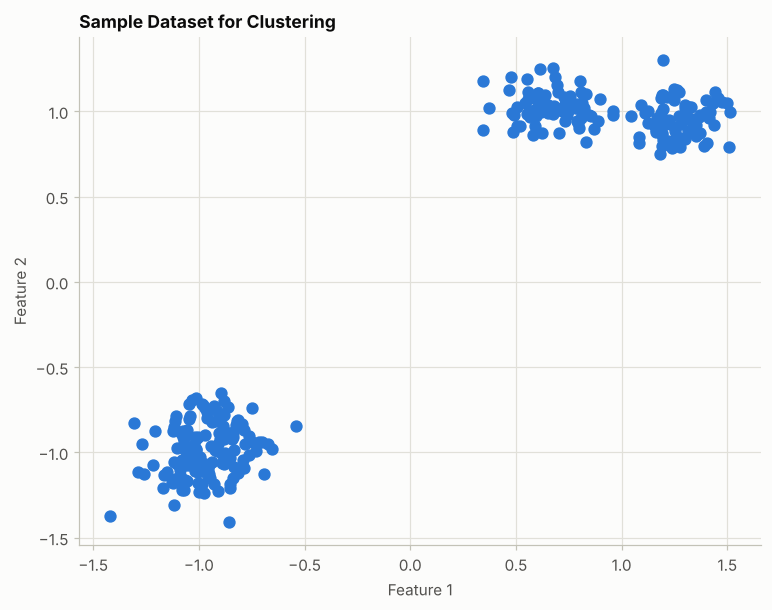

In [3]:
# BOOK CODE (p. 255): visualize the raw data
# Visualize the raw data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title("Sample Dataset for Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**Output analysis.**

* The listing prints nothing. Figure 10.1 shows the 300 standardized points (both axes run from about -1.5 to 1.5) as **two clearly separated groups**: a group in the lower left that looks like a single blob, and a group in the upper right that looks like two blobs side by side. The four centres of the generator are not all visible by eye; the next extra measures why.
* `StandardScaler` gives each feature a mean of 0 and a variance of 1, so the plot is centred on the origin and both features have the same weight in the distances.

### Extra: experiments for recipe 1

**(a) The geometry behind Figure 10.1.** `make_blobs` returns the generating centre of every point, which the book discards (`X, _ = ...`). With the labels, the picture can be read: how far apart are the four centres, measured in standard deviations of the blobs?

blob sizes: [75, 75, 75, 75]
true centres (before scaling): [[1.75, 4.03], [-6.34, -9.2], [-5.9, -7.86], [4.64, 3.59]]

distance between the centres, in blob standard deviations (sigma = 0.60):
      0     1     2     3
0   0.0  25.9  23.6   4.9
1  25.9   0.0   2.4  28.1
2  23.6   2.4   0.0  25.9
3   4.9  28.1  25.9   0.0


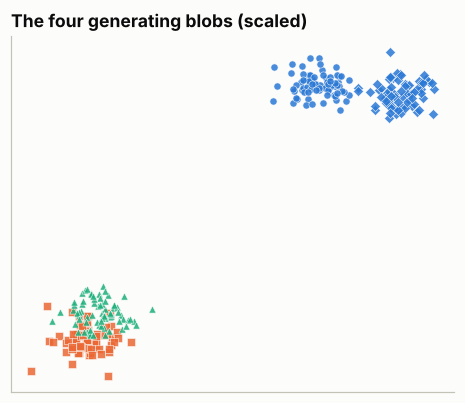

In [4]:
# EXTRA: (a) the true labels of the generator and the distances between the four blob centres
X_raw, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)
assert np.allclose(StandardScaler().fit_transform(X_raw), X)   # the same data as the book's X

centres = np.array([X_raw[y_true == k].mean(axis=0) for k in range(4)])
gaps = pd.DataFrame(np.linalg.norm(centres[:, None] - centres[None], axis=2) / 0.60, columns=range(4), index=range(4))
print("blob sizes:", np.bincount(y_true).tolist())
print("true centres (before scaling):", np.round(centres, 2).tolist())
print("\ndistance between the centres, in blob standard deviations (sigma = 0.60):")
print(gaps.round(1).to_string())

fig, ax = plt.subplots(figsize=(5.2, 4.2))
scatter_clusters(ax, X, y_true, title="The four generating blobs (scaled)")
plt.show()

**(b) Why the book standardizes.** Suppose feature 2 had been recorded in other units (centimetres instead of metres, a factor of 100). K-means on the raw values, and on the standardized values, then give very different answers. The adjusted Rand index (ARI, recipe 5) measures the agreement with the true blobs: 1 is a perfect match, 0 is chance level.

In [5]:
# EXTRA: (b) K-means with a feature in other units, with and without standardization
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

X_units = X_raw * np.array([1.0, 100.0])          # feature 2 in 'centimetres'
rows = []
for name, data in [("raw values, original units", X_raw),
                   ("raw values, feature 2 times 100", X_units),
                   ("standardized, original units", StandardScaler().fit_transform(X_raw)),
                   ("standardized, feature 2 times 100", StandardScaler().fit_transform(X_units))]:
    labels = KMeans(n_clusters=4, random_state=2024).fit_predict(data)
    rows.append({"data given to K-means": name, "ARI with the true blobs": adjusted_rand_score(y_true, labels)})
print(pd.DataFrame(rows).set_index("data given to K-means").round(3).to_string())

                                   ARI with the true blobs
data given to K-means                                     
raw values, original units                           0.814
raw values, feature 2 times 100                      0.496
standardized, original units                         0.801
standardized, feature 2 times 100                    0.801


**(c) Structure that is not there.** The next figure runs K-means with $K = 4$ on the blobs and on 300 points drawn uniformly from a square. Both come back as four tidy groups. The silhouette score (recipe 5) is the only hint that one of them is not real.

Blobs         : K-means with k=4, cluster sizes [71, 77, 73, 79], inertia 7.3, silhouette 0.531
Uniform noise : K-means with k=4, cluster sizes [73, 89, 67, 71], inertia 102.7, silhouette 0.415


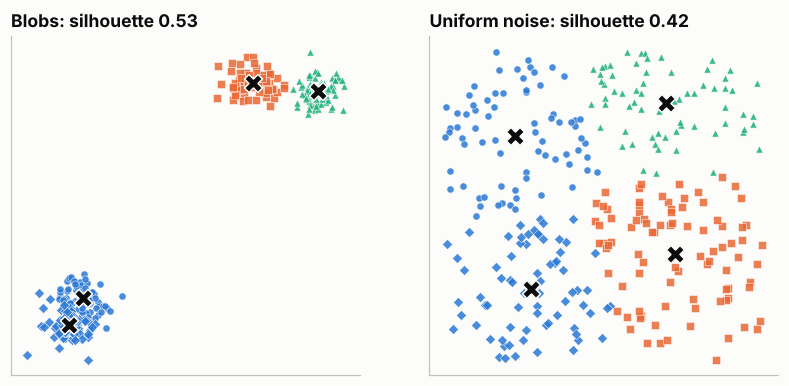

In [6]:
# EXTRA: (c) K-means finds four clusters in uniform noise too
from sklearn.metrics import silhouette_score

uniform = np.random.RandomState(2024).uniform(-1.5, 1.5, size=(300, 2))
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, data) in zip(axes, [("Blobs", X), ("Uniform noise", uniform)]):
    model = KMeans(n_clusters=4, random_state=2024).fit(data)
    scatter_clusters(ax, data, model.labels_, centers=model.cluster_centers_,
                     title=f"{title}: silhouette {silhouette_score(data, model.labels_):.2f}")
    print(f"{title:14s}: K-means with k=4, cluster sizes {np.bincount(model.labels_).tolist()}, inertia {model.inertia_:.1f}, silhouette {silhouette_score(data, model.labels_):.3f}")
plt.show()

**Analysis of the extras.**

* **(a)** The generator drew 75 points around each of the four centres. Blobs 1 and 2 are only **2.4 standard deviations apart** (about 1.4 units with a spread of 0.60), so they overlap; blobs 0 and 3 are 4.9 standard deviations apart, touching but distinct; the two pairs are 24 to 28 standard deviations from each other. The data therefore holds **two very clear groups**, each made of two blobs. This explains the look of Figure 10.1 and, later, why the elbow and the silhouette point to 2 or 3 clusters and not to 4.
* **(b)** On the raw values K-means agrees with the true blobs at an ARI of 0.814. If the second feature is recorded in other units (a factor of 100), the distances are dominated by that feature and the ARI falls to **0.496**. After standardization the result is **0.801 in both cases**: the book's `StandardScaler` makes the clustering independent of the units. (The small difference between 0.814 and 0.801 is a change of the geometry, not an improvement: the two features had different spreads.)
* **(c)** K-means with $k = 4$ returns four tidy groups of 73, 89, 67 and 71 points on uniform noise, as it does on the blobs. The silhouette is lower for the noise (0.415 against 0.531), but the difference is not large: by the usual reading, 0.25 to 0.5 is weak structure and 0.5 to 0.7 reasonable. A K-means result is a partition of the space first, and evidence of clusters only if the metrics and the picture agree.

---
## 2. K-means clustering

### Summary

* K-means "partitions data into a predefined number of clusters". It places centroids, assigns each point to the nearest one, moves each centroid to the mean of its points, and repeats until nothing changes. It "is efficient and works best when clusters are convex, isotropic, and roughly equal in size... which also can be its greatest weakness".
* **Getting ready** — reuse the standardized blobs and import `KMeans`.
* **How to do it** — `KMeans(n_clusters=4, random_state=2024).fit_predict(X)`, and a scatter plot with the four centroids as black crosses (Figure 10.2). `n_clusters` is the only required argument, which "implies that we know or at least can estimate the number of clusters beforehand".
* **How it works** — initialization (random or k-means++), an assignment step (nearest centroid, usually by Euclidean distance) and an update step (the centroid becomes the mean of its points); it stops when assignments stop changing or at the maximum number of iterations. "K-means minimizes within-cluster variance (inertia)."
* **There's more** — the **elbow method**: plot the inertia for $k = 1, \dots, 9$ and look for the point where "adding more clusters yields diminishing returns" (Figure 10.3). The book reads the chart as "two to three clusters are the optimal choices for k".
* **Hands-on exercises** — six steps, ending with a different initialization method and different values of $k$.

### Theory: Lloyd's algorithm, k-means++ and what "inertia" optimizes

**The objective.** For a partition $C_1, \dots, C_K$ with centroids $\boldsymbol{\mu}_k$, K-means minimizes the **inertia** (within-cluster sum of squares)

$$
J = \sum_{k=1}^{K} \sum_{\mathbf{x}_i \in C_k} \lVert \mathbf{x}_i - \boldsymbol{\mu}_k \rVert^2 .
$$

**Lloyd's algorithm** alternates two steps:

1. **Assignment** — $c_i = \arg\min_k \lVert \mathbf{x}_i - \boldsymbol{\mu}_k \rVert^2$: every point joins the nearest centroid.
2. **Update** — $\boldsymbol{\mu}_k = \frac{1}{\lvert C_k \rvert} \sum_{\mathbf{x}_i \in C_k} \mathbf{x}_i$: every centroid moves to the mean of its points.

Each step cannot increase $J$: the assignment step picks, for fixed centroids, the best cluster of each point; the mean is, for fixed clusters, the point that minimizes the sum of squared distances (set the derivative of $\sum_i \lVert \mathbf{x}_i - \boldsymbol{\mu} \rVert^2$ to zero). The number of partitions is finite, so the algorithm **converges**, but only to a **local minimum**: the result depends on the starting centroids, and finding the global minimum is NP-hard in general (Aloise et al., 2009).

**Shape of the clusters.** The points that are closer to centroid $k$ than to any other form a **Voronoi cell**, a convex polygon whose borders are the perpendicular bisectors of the centroids. K-means can only produce such convex, linearly separated clusters. Because it measures the plain Euclidean distance with the same weight in every direction and for every cluster, it implicitly assumes **round clusters of similar spread**. It is also sensitive to outliers (the mean is not robust) and to the scale of the features.

**Initialization.** Random starting points can put two centroids in one blob and none in another. **k-means++** (Arthur and Vassilvitskii, 2007) chooses the first centroid uniformly, then each next centroid with probability proportional to $D(\mathbf{x})^2$, the squared distance to the nearest centroid already chosen. Far-away points are likely to be picked, so the centroids start spread out, and the expected inertia of the start is within a factor $O(\log K)$ of the optimum. Scikit-learn's default is `init='k-means++'` with `n_init='auto'`: one run for k-means++ and ten for `init='random'`, keeping the run with the lowest inertia.

**Cost.** One iteration costs $O(n K d)$, so K-means scales to large data. `MiniBatchKMeans` (Sculley, 2010) updates the centroids from small random batches and trades a little inertia for a large saving in time.

**Choosing $K$.** The inertia **always decreases** as $K$ grows (it is 0 for $K = n$), so its minimum cannot pick $K$. The **elbow method** looks for the bend of the inertia curve, which is a judgement call. The **silhouette score** (recipe 5) is a second criterion; the **gap statistic** (Tibshirani et al., 2001) and the BIC of a Gaussian mixture (recipe 7) are others. They often disagree, as the extras show.

**A link to recipe 7.** K-means is the limit of a Gaussian mixture model whose clusters are spherical with the same variance, when that variance goes to zero and the soft assignments become hard.

### Book code (pp. 256–259)

In [7]:
# BOOK CODE (p. 257): load KMeans (the dataset X is the one of recipe 1)
# Load the libraries
from sklearn.cluster import KMeans
# Reuse the dataset from the previous section
# Dataset already loaded and scaled as X

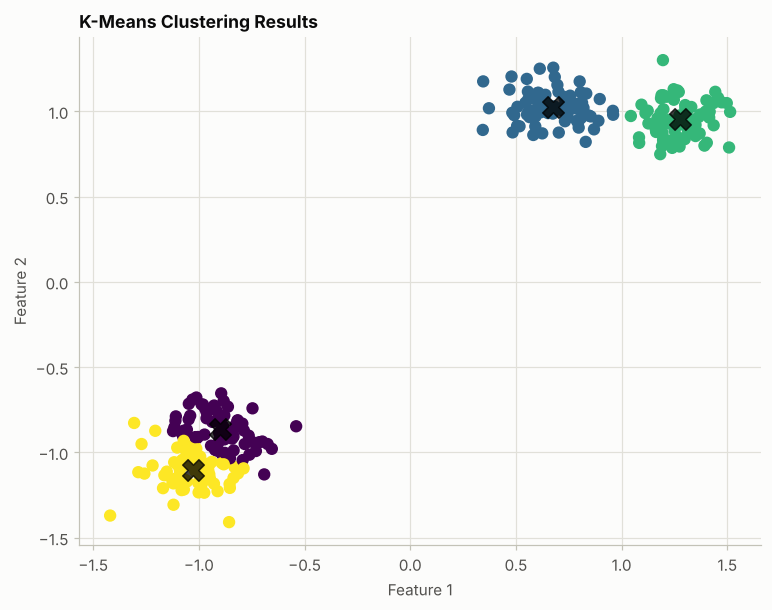

In [8]:
# BOOK CODE (pp. 257-258): apply K-means and plot the clusters with their centroids
# Apply K-Means clustering
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

# Plot the clustered data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.75, marker='X')
plt.title("K-Means Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

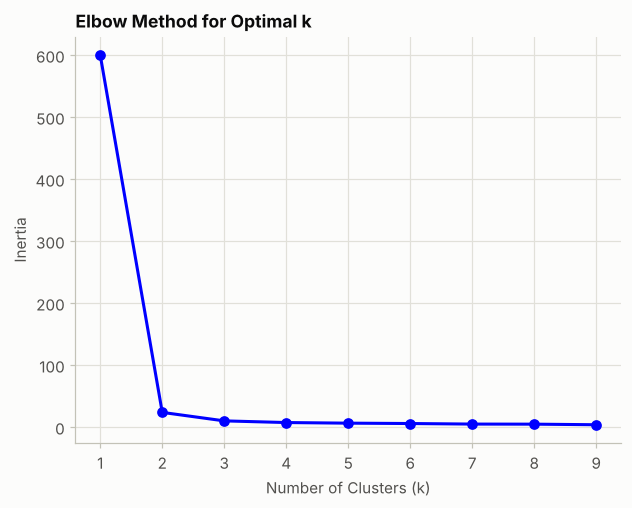

In [9]:
# BOOK CODE (p. 259): the elbow method
# Calculate and plot clustering inertia
inertia = []
k_values = range(1, 10)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=2024)
    km.fit(X)
    inertia.append(km.inertia_)

plt.plot(k_values, inertia, 'bo-')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

In [10]:
# EXTRA: inspect what the book's code produced
print(f"K-means with k=4: inertia {kmeans.inertia_:.3f} after {kmeans.n_iter_} iterations; cluster sizes {np.bincount(y_kmeans).tolist()}")
print(f"defaults: init={kmeans.init!r}, n_init={kmeans.n_init!r}, algorithm={kmeans.algorithm!r}, tol={kmeans.tol}")
print(f"agreement of the clusters with the generating blobs: ARI {adjusted_rand_score(y_true, y_kmeans):.3f}")
print("inertia for k = 1..9:", [round(value, 1) for value in inertia])
print(f"total variance of the standardized data (inertia for k = 1): {X.var(axis=0).sum() * len(X):.1f}")

K-means with k=4: inertia 7.295 after 4 iterations; cluster sizes [71, 77, 73, 79]
defaults: init='k-means++', n_init='auto', algorithm='lloyd', tol=0.0001
agreement of the clusters with the generating blobs: ARI 0.801
inertia for k = 1..9: [600.0, 23.7, 10.0, 7.3, 6.3, 5.7, 4.8, 4.7, 3.8]
total variance of the standardized data (inertia for k = 1): 600.0


**Output analysis.**

* K-means with $k = 4$ converges in **4 iterations** to an inertia of 7.295, with clusters of 71, 77, 73 and 79 points (the generator drew 75 per blob). The agreement with the generator is an ARI of **0.801**, not 1: blobs 1 and 2 overlap, and recipe 5's contingency table shows that about 22 of their points land in the wrong cluster.
* The printed defaults are `init='k-means++'`, `n_init='auto'` and `algorithm='lloyd'`. The book's sentence "K-means randomly creates centroids" describes `init='random'`, not the default.
* The inertia for $k = 1$ is **600.0**, the total variance of the standardized data (300 samples times 2 features times a variance of 1): a useful check. Then it falls to 23.7 ($k = 2$), 10.0, 7.3, 6.3, ... The largest drop by far is from 1 to 2, a smaller one from 2 to 3, and the bend at $k = 4$ is faint. The book's reading, "two to three clusters are the optimal choices", agrees with the curve; the generator has 4 blobs, but two of them overlap.

### Extra: experiments for recipe 2

**(a) Lloyd's algorithm by hand.** The loop below is the two steps of the theory, written with NumPy and started from the same four points as `KMeans(init=..., n_init=1)`. It reproduces the library's inertia and labels, and the inertia never increases. The figure shows the assignment at the start, after the first iterations and at the end.

by hand : 7 assignment steps, final inertia 7.293907
KMeans  : 7 iterations, final inertia 7.293907
same clusters as KMeans: True; inertia never increases: True
inertia after each assignment step: [14.25, 7.8, 7.44, 7.32, 7.3, 7.29, 7.29]


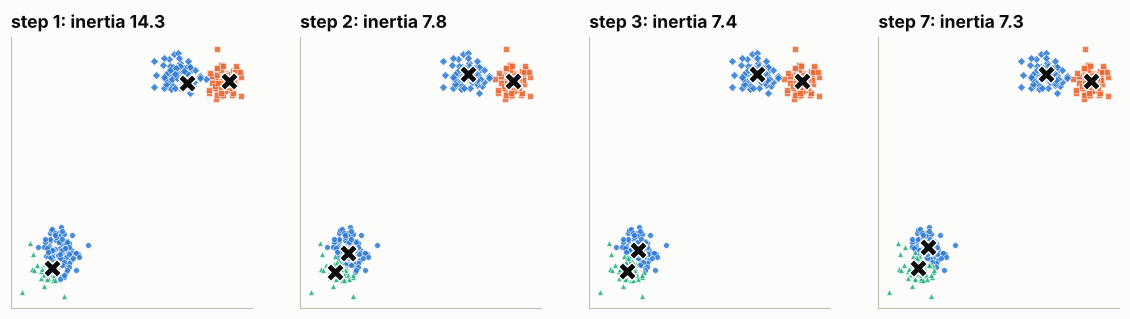

In [11]:
# EXTRA: (a) Lloyd's algorithm in NumPy, compared with KMeans started from the same centroids
from scipy.spatial.distance import cdist

start = X[np.random.RandomState(0).choice(len(X), size=4, replace=False)]     # four random data points
reference = KMeans(n_clusters=4, init=start, n_init=1, algorithm="lloyd", tol=0).fit(X)

centroids = start.copy()
history, snapshots = [], []
for iteration in range(100):
    labels = cdist(X, centroids).argmin(axis=1)                                 # assignment step
    history.append(((X - centroids[labels]) ** 2).sum())                        # inertia of this assignment
    snapshots.append((labels.copy(), centroids.copy()))
    new_centroids = np.array([X[labels == k].mean(axis=0) for k in range(4)])  # update step
    if np.allclose(new_centroids, centroids):
        break
    centroids = new_centroids

print(f"by hand : {len(history)} assignment steps, final inertia {history[-1]:.6f}")
print(f"KMeans  : {reference.n_iter_} iterations, final inertia {reference.inertia_:.6f}")
print(f"same clusters as KMeans: {adjusted_rand_score(labels, reference.labels_) == 1.0}; inertia never increases: {bool(np.all(np.diff(history) <= 1e-12))}")
print("inertia after each assignment step:", [round(float(value), 2) for value in history])

picked = [0, 1, 2, len(snapshots) - 1]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, step in zip(axes, picked):
    labels_step, centroids_step = snapshots[step]
    scatter_clusters(ax, X, labels_step, centers=centroids_step, title=f"step {step + 1}: inertia {history[step]:.1f}", size=14)
plt.show()

**(b) The initialization lottery.** The same K-means is started 100 times with different seeds, with random starting points and with k-means++, using one start per run (`n_init=1`) and ten starts (`n_init=10`, the library keeps the best). A run is "optimal" if its inertia is within 0.1% of the best inertia found in all runs.

best inertia found: 7.292

                  median inertia  worst inertia  share of optimal runs
init      n_init                                                      
random    1                9.008         20.762                   0.33
          10               7.293          9.003                   0.98
k-means++ 1                7.296          9.303                   0.77
          10               7.293          7.295                   1.00


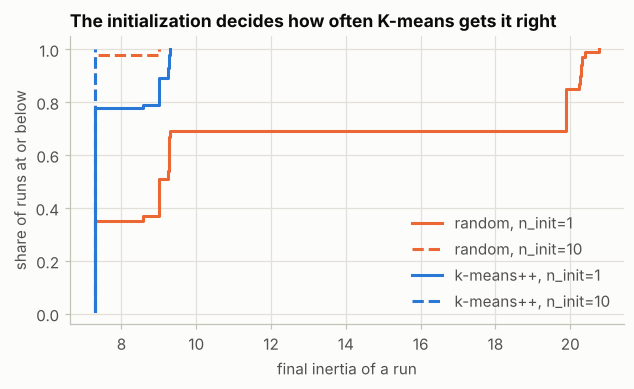

In [12]:
# EXTRA: (b) final inertia over 100 seeds for two initializations and two values of n_init
seeds = range(100)
results = {}
for init in ("random", "k-means++"):
    for n_init in (1, 10):
        results[(init, n_init)] = np.array([KMeans(n_clusters=4, init=init, n_init=n_init, random_state=seed).fit(X).inertia_ for seed in seeds])
best = min(values.min() for values in results.values())

rows = [{"init": init, "n_init": n_init, "median inertia": np.median(v), "worst inertia": v.max(), "share of optimal runs": np.mean(v < best * 1.001)}
        for (init, n_init), v in results.items()]
print(f"best inertia found: {best:.3f}\n")
print(pd.DataFrame(rows).set_index(["init", "n_init"]).round(3).to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.4))
for (init, n_init), values, color, style in zip(results, results.values(), [PALETTE[1], PALETTE[1], PALETTE[0], PALETTE[0]], ["-", "--", "-", "--"]):
    ax.step(np.sort(values), np.arange(1, len(values) + 1) / len(values), where="post", color=color, linestyle=style, label=f"{init}, n_init={n_init}")
ax.set_xlabel("final inertia of a run")
ax.set_ylabel("share of runs at or below")
ax.set_title("The initialization decides how often K-means gets it right")
ax.legend(loc="lower right")
plt.show()

**(c) The elbow against the silhouette.** The inertia curve of the book, next to the silhouette score and to the ARI with the true blobs, for $k = 2, \dots, 9$. The silhouette and the ARI are introduced in recipe 5; here they only help to read the elbow.

   inertia  drop from k-1  silhouette  ARI with the true blobs
k                                                             
2   23.679        576.321       0.880                    0.497
3    9.993         13.687       0.784                    0.697
4    7.295          2.697       0.531                    0.801
5    6.305          0.990       0.451                    0.709
6    5.724          0.582       0.400                    0.630
7    4.827          0.896       0.420                    0.601
8    4.685          0.142       0.418                    0.597
9    3.752          0.933       0.368                    0.464

k with the highest silhouette: 2; k with the highest ARI: 4


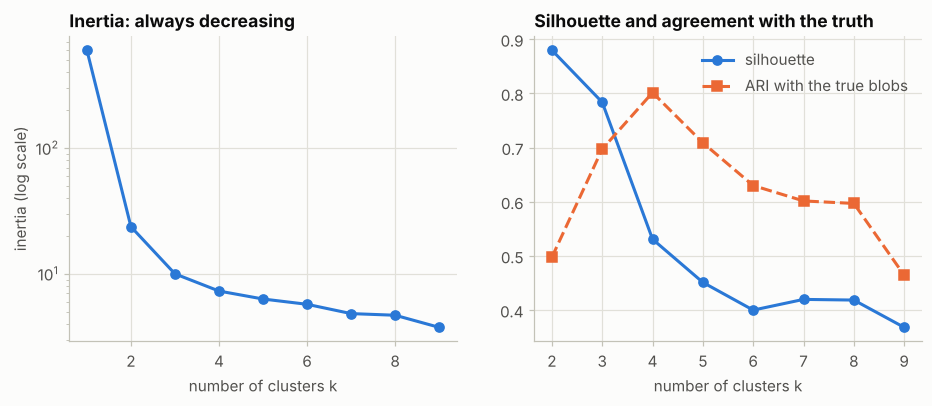

In [13]:
# EXTRA: (c) three ways to choose k, and the truth (4 blobs)
rows = []
for k in range(2, 10):
    labels_k = KMeans(n_clusters=k, random_state=2024).fit_predict(X)
    rows.append({"k": k, "inertia": inertia[k - 1], "drop from k-1": inertia[k - 2] - inertia[k - 1],
                 "silhouette": silhouette_score(X, labels_k), "ARI with the true blobs": adjusted_rand_score(y_true, labels_k)})
elbow_table = pd.DataFrame(rows).set_index("k")
print(elbow_table.round(3).to_string())
print(f"\nk with the highest silhouette: {elbow_table['silhouette'].idxmax()}; k with the highest ARI: {elbow_table['ARI with the true blobs'].idxmax()}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].plot(range(1, 10), inertia, "o-", color=PALETTE[0])
axes[0].set_yscale("log")
axes[0].set_xlabel("number of clusters k")
axes[0].set_ylabel("inertia (log scale)")
axes[0].set_title("Inertia: always decreasing")
axes[1].plot(elbow_table.index, elbow_table["silhouette"], "o-", color=PALETTE[0], label="silhouette")
axes[1].plot(elbow_table.index, elbow_table["ARI with the true blobs"], "s--", color=PALETTE[1], label="ARI with the true blobs")
axes[1].set_xlabel("number of clusters k")
axes[1].set_title("Silhouette and agreement with the truth")
axes[1].legend(loc="upper right")
plt.show()

**(d) Where K-means breaks.** Three datasets, each violating one assumption of the theory: **stretched** clusters (a linear transformation of the blobs), clusters of **unequal spread**, and a **small, tight cluster next to a large, loose one** (500 and 50 points, constructed for this experiment). K-means is compared with a Gaussian mixture (recipe 7), which models an elliptical shape and a spread per cluster.

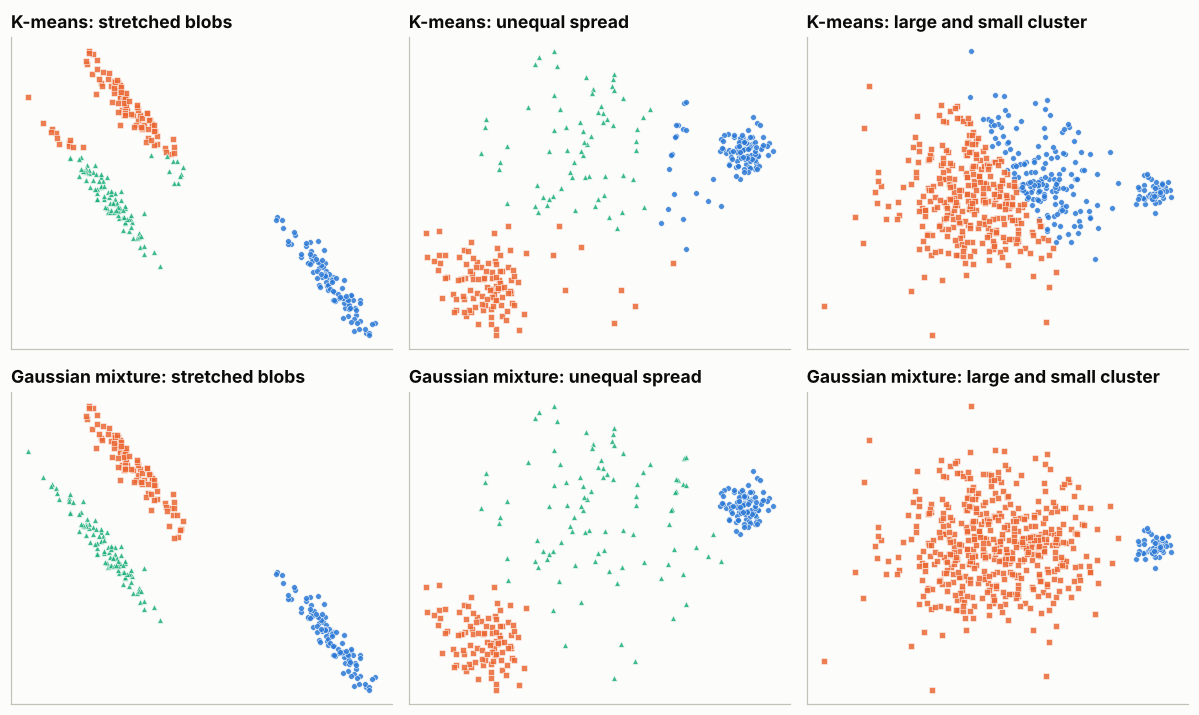

                         K-means ARI  Gaussian mixture ARI
dataset                                                   
stretched blobs                0.803                 1.000
unequal spread                 0.722                 0.951
large and small cluster        0.118                 0.987

large and small cluster: inertia of the true partition 836.4, inertia found by K-means 758.1


In [14]:
# EXTRA: (d) three violations of K-means' assumptions, K-means against a Gaussian mixture
from sklearn.mixture import GaussianMixture

Xa, ya = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=170)
stretched = Xa @ np.array([[0.6, -0.64], [-0.4, 0.85]])
unequal_spread, y_spread = make_blobs(n_samples=300, centers=3, cluster_std=[1.0, 2.5, 0.5], random_state=170)
rng = np.random.RandomState(2024)
big_and_small = np.vstack([rng.normal([0, 0], 1.5, size=(500, 2)), rng.normal([5.0, 0], 0.3, size=(50, 2))])
y_big_small = np.r_[np.zeros(500, dtype=int), np.ones(50, dtype=int)]

cases = {"stretched blobs": (stretched, ya, 3), "unequal spread": (unequal_spread, y_spread, 3), "large and small cluster": (big_and_small, y_big_small, 2)}
fig, axes = plt.subplots(2, 3, figsize=(11, 6.6))
rows = []
for column, (name, (data, truth, k)) in enumerate(cases.items()):
    data = StandardScaler().fit_transform(data)
    kmeans_labels = KMeans(n_clusters=k, random_state=2024).fit_predict(data)
    gmm_labels = GaussianMixture(n_components=k, random_state=2024).fit_predict(data)
    scatter_clusters(axes[0, column], data, kmeans_labels, title=f"K-means: {name}", size=14)
    scatter_clusters(axes[1, column], data, gmm_labels, title=f"Gaussian mixture: {name}", size=14)
    rows.append({"dataset": name, "K-means ARI": adjusted_rand_score(truth, kmeans_labels), "Gaussian mixture ARI": adjusted_rand_score(truth, gmm_labels)})
plt.tight_layout()
plt.show()
print(pd.DataFrame(rows).set_index("dataset").round(3).to_string())

# why K-means cuts the wrong cluster: its partition has a lower inertia than the true one
data_bs = StandardScaler().fit_transform(big_and_small)
inertia_true = sum(((data_bs[y_big_small == k] - data_bs[y_big_small == k].mean(axis=0)) ** 2).sum() for k in (0, 1))
print(f"\nlarge and small cluster: inertia of the true partition {inertia_true:.1f}, inertia found by K-means {KMeans(n_clusters=2, random_state=2024).fit(data_bs).inertia_:.1f}")

**Analysis of the extras.**

* **(a)** The by-hand loop reproduces the library: the same final inertia (7.293907) and the same clusters, in 7 assignment steps. The inertia goes 14.25, 7.80, 7.44, 7.32, 7.30, 7.29, 7.29: it **never increases**, and most of the progress is made in the first two steps.
* **(b)** With **one start**, random initialization reaches the best inertia in only **33%** of 100 runs (median 9.01, worst 20.76, nearly three times the best), and k-means++ in **77%** (median 7.296, worst 9.30). With **ten starts** (`n_init=10`, the library keeps the best) random reaches it in 98% and k-means++ in 100%. A bad run is a local minimum, for example two centroids inside one blob. The book's `random_state=2024` fixes one lottery ticket: here it is a good one.
* **(c)** The silhouette is highest at $k = 2$ (0.880) and the ARI with the true blobs at $k = 4$ (0.801). The inertia drops by 576 from $k = 1$ to $k = 2$, by 14 to $k = 3$ and by 2.7 to $k = 4$: the elbow is at 2, with a second, smaller bend at 3. This is the book's "two to three". Neither the elbow nor the silhouette finds 4, because two blobs overlap; only the ARI, which needs the labels, does. The criteria answer different questions: "how many clearly separated groups?" and "how many blobs did the generator draw?".
* **(d)** The assumptions are real. On **stretched** blobs K-means scores an ARI of 0.803 and the Gaussian mixture 1.000. With **unequal spread** it scores 0.722 against 0.951. With a **small tight cluster beside a large loose one** (constructed for this experiment) K-means scores **0.118** against 0.987: splitting the large cluster in two saves more inertia than giving the 50 tightly packed points a centroid of their own, so K-means cuts the wrong cluster: the partition it finds has a lower inertia than the true one (printed above). A model with a covariance per cluster (recipe 7) does not have this problem.

---
## 3. Hierarchical clustering

### Summary

* **Hierarchical clustering** "builds nested clusters by either merging or splitting them successively". It is "especially useful when the number of clusters is not known in advance", and it gives a tree, the **dendrogram**. Two approaches exist: **agglomerative** (bottom-up) and **divisive** (top-down). Agglomerative clustering is the common one and the one scikit-learn supports directly.
* **Getting ready** — import `AgglomerativeClustering` from scikit-learn and `dendrogram` and `linkage` from SciPy; reuse the standardized blobs.
* **How to do it** — `AgglomerativeClustering(n_clusters=4)` with a scatter plot, then SciPy's `linkage(X, method='ward')` and a dendrogram (Figures 10.4 and 10.5). "We can specify a number of clusters, or we can specify a distance metric threshold to create a cutoff point... one or the other."
* **How it works** — every point starts as its own cluster; at each step the two closest clusters are merged according to a **linkage criterion**, until one cluster remains or a stopping condition is met. The linkages: **Ward** (minimizes the variance of the merged clusters; the default), **complete** (maximum distance between points of two clusters), **average** (mean distance over all pairs) and **single** (minimum distance). Cutting the dendrogram at a height gives the clusters.
* **There's more** — "if clusters are well-separated, the height of the linkage distances will show clear gaps". The book states that scikit-learn has no native divisive clustering.
* **Hands-on exercises** — six steps: apply `AgglomerativeClustering` with different linkages, draw the dendrogram, and cut it at different levels.

### Theory: linkages, the dendrogram and the cost

**The algorithm.** Start with $n$ clusters, one per sample. Repeat $n - 1$ times: compute the dissimilarity $D(A, B)$ of every pair of current clusters, merge the pair with the smallest $D$, and record the value of $D$ as the **height** of the merge. The sequence of merges is the **dendrogram**: leaves are samples, each merge joins two branches at its height, and cutting the tree at height $h$ (or choosing $K$) gives a flat clustering. The procedure is greedy and **deterministic**: there is no random start, and a merge is never undone.

**The four linkages** differ only in $D(A, B)$, with $d$ the Euclidean distance between two points:

$$
D_{\text{single}} = \min_{a \in A,\, b \in B} d(a, b), \qquad
D_{\text{complete}} = \max_{a \in A,\, b \in B} d(a, b), \qquad
D_{\text{average}} = \frac{1}{\lvert A \rvert \lvert B \rvert} \sum_{a \in A} \sum_{b \in B} d(a, b),
$$

$$
D_{\text{Ward}} = \frac{n_A\, n_B}{n_A + n_B} \, \lVert \boldsymbol{\mu}_A - \boldsymbol{\mu}_B \rVert^2 , \qquad n_A = \lvert A \rvert, \; n_B = \lvert B \rvert .
$$

**Ward's criterion** is the **increase of the total within-cluster sum of squares** (the inertia of recipe 2) caused by the merge. Ward's method is therefore a hierarchical relative of K-means: it prefers compact, round clusters of similar size, and it requires Euclidean distances. SciPy reports the height of a Ward merge as $\sqrt{2\, D_{\text{Ward}}}$, which is what the dendrogram of the book shows.

* **Single linkage** joins two clusters through their two closest points. It can follow **curved** shapes, but it suffers from **chaining**: a thin bridge of noise points merges two clusters that are otherwise far apart.
* **Complete linkage** is governed by the farthest points, so it produces compact clusters of similar diameter and is sensitive to outliers.
* **Average linkage** (UPGMA) is a compromise between the two.
* All four are special cases of the Lance-Williams recurrence, which updates the dissimilarities after a merge without going back to the points.

**Reading a dendrogram.** A long vertical stretch without any merge means that the clusters below it are far apart: cutting there is natural. Equivalently, look for a **gap** in the sequence of the last merge heights. `AgglomerativeClustering(n_clusters=None, distance_threshold=h)` cuts at the height $h$ instead of asking for $K$.

**Cost.** The algorithm needs the $n \times n$ distance matrix: $O(n^2)$ memory and between $O(n^2 \log n)$ and $O(n^3)$ time, so it suits datasets of a few thousand points. A sparse `connectivity` graph (for example k-nearest neighbours) restricts the possible merges and makes it faster.

**Divisive clustering** goes the other way, splitting one cluster at a time. The book says that scikit-learn has no divisive method; since version 1.1 it has one, `BisectingKMeans`, which repeatedly splits a cluster in two with 2-means. Its partitions for $K = 2, 3, 4, \dots$ are nested by construction, so it also yields a hierarchy. The extra below checks this.

### Book code (pp. 260–263)

In [15]:
# BOOK CODE (p. 260): load the libraries (the dataset X is still the one of recipe 1)
# Load the libraries
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Reuse the dataset from the earlier section
# Dataset already loaded and scaled as X

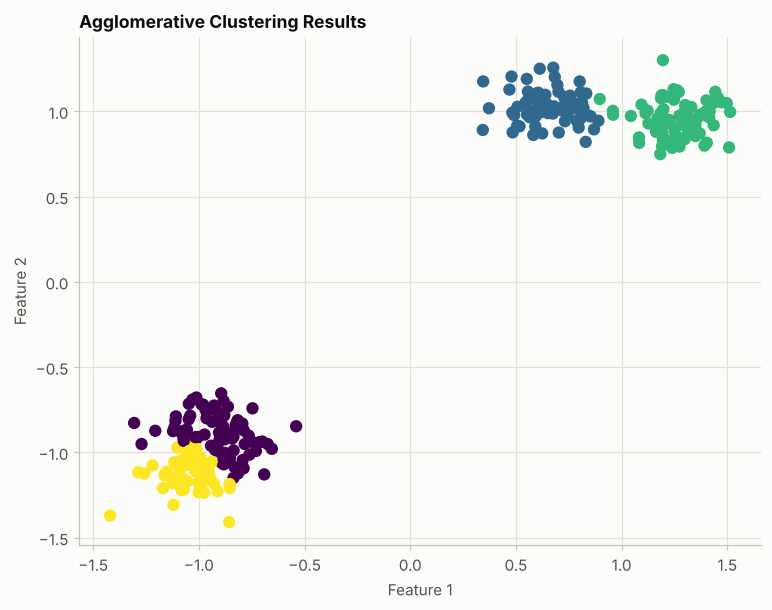

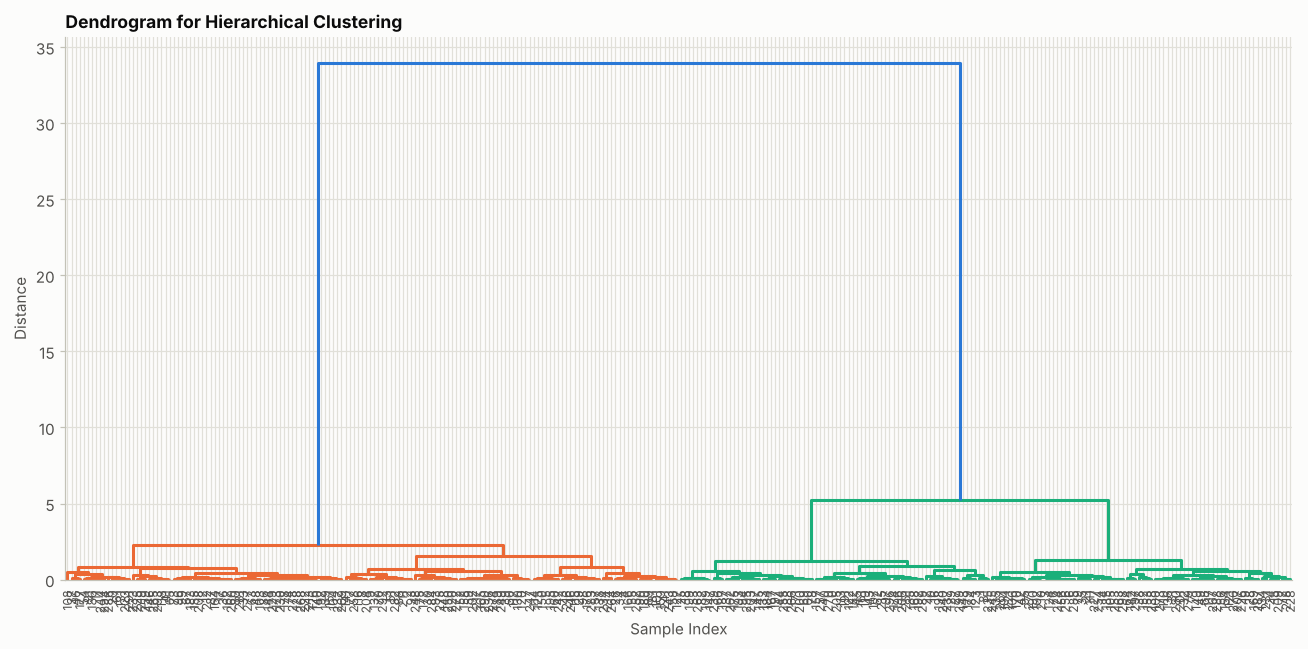

In [16]:
# BOOK CODE (pp. 261-262): agglomerative clustering, scatter plot and dendrogram
# Apply agglomerative clustering
agg = AgglomerativeClustering(n_clusters=4)
y_agg = agg.fit_predict(X)

# Plot the clustered data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_agg, cmap='viridis', s=50)
plt.title("Agglomerative Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Generate the dendrogram using SciPy
linked = linkage(X, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(linked, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrogram for Hierarchical Clustering")
plt.xlabel("Sample Index")
plt.ylabel("Distance")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [17]:
# EXTRA: inspect what the book's code produced
print(f"agglomerative clustering, {agg.n_clusters_} clusters of sizes {np.bincount(y_agg).tolist()}; defaults: linkage={agg.linkage!r}, metric={agg.metric!r}")
print(f"agreement with K-means (k=4): ARI {adjusted_rand_score(y_kmeans, y_agg):.3f}; with the true blobs: ARI {adjusted_rand_score(y_true, y_agg):.3f}")
print(f"linkage matrix: {linked.shape[0]} merges (one fewer than the {len(X)} samples); each row = (cluster a, cluster b, height, size)")
print(f"first merges:\n{np.round(linked[:3], 3)}\nlast merges:\n{np.round(linked[-3:], 3)}")

agglomerative clustering, 4 clusters of sizes [82, 74, 76, 68]; defaults: linkage='ward', metric='euclidean'
agreement with K-means (k=4): ARI 0.882; with the true blobs: ARI 0.793
linkage matrix: 299 merges (one fewer than the 300 samples); each row = (cluster a, cluster b, height, size)
first merges:
[[4.30e+01 1.07e+02 1.00e-03 2.00e+00]
 [1.26e+02 1.40e+02 2.00e-03 2.00e+00]
 [1.20e+01 2.12e+02 2.00e-03 2.00e+00]]
last merges:
[[591.    595.      2.254 150.   ]
 [593.    594.      5.208 150.   ]
 [596.    597.     33.951 300.   ]]


**Output analysis.**

* Ward clustering with $k = 4$ finds clusters of 82, 74, 76 and 68 points. It agrees with K-means at an ARI of 0.882 and with the true blobs at 0.793 (K-means: 0.801), so the overlap of blobs 1 and 2 limits it as well.
* The linkage matrix has 299 rows, one merge each, with the two merged clusters, the height and the size of the new cluster. The first merges join almost identical points at heights of 0.001 to 0.002. The last three are at heights **2.25**, **5.21** and **33.95**: two groups of 150 points are formed at the low heights, then joined at 33.95.
* In the book's dendrogram, the 300 leaf labels overlap and cannot be read; what is legible is the top. A single very long vertical line (33.95) joins two halves, and each half is split at a much lower height (5.21 and 2.25). That is the "clear gap" of the book's "There's more": the data supports 2 clusters strongly, and a finer split only weakly.

### Extra: experiments for recipe 3

**(a) Ward's method by hand.** The cell merges the 30 first points with the definition of the theory (at every step, the pair of clusters with the smallest increase of the sum of squares) and compares the heights with SciPy's linkage matrix, using $\sqrt{2\, D_{\text{Ward}}}$. It also checks that $D_{\text{Ward}}$ is really the increase of the inertia.

In [18]:
# EXTRA: (a) Ward's method in NumPy on 30 points, compared with SciPy
points = X[:30]
members = {i: [i] for i in range(len(points))}
sse = lambda ids: ((points[ids] - points[ids].mean(axis=0)) ** 2).sum()
heights, next_id, formula_matches_sse = [], len(points), True
while len(members) > 1:
    best = None
    for a in members:
        for b in members:
            if a < b:
                n_a, n_b = len(members[a]), len(members[b])
                cost = n_a * n_b / (n_a + n_b) * ((points[members[a]].mean(axis=0) - points[members[b]].mean(axis=0)) ** 2).sum()
                if best is None or cost < best[0]:
                    best = (cost, a, b)
    cost, a, b = best
    formula_matches_sse &= bool(np.isclose(cost, sse(members[a] + members[b]) - sse(members[a]) - sse(members[b])))
    heights.append(np.sqrt(2 * cost))
    members[next_id] = members.pop(a) + members.pop(b)
    next_id += 1

scipy_heights = linkage(points, method="ward")[:, 2]
print(f"29 merges by hand equal SciPy's heights: {np.allclose(heights, scipy_heights)}")
print(f"the Ward cost of every merge equals the increase of the sum of squares: {formula_matches_sse}")
print("first heights by hand :", np.round(heights[:5], 4).tolist())
print("first heights, SciPy  :", np.round(scipy_heights[:5], 4).tolist())

29 merges by hand equal SciPy's heights: True
the Ward cost of every merge equals the increase of the sum of squares: True
first heights by hand : [0.0278, 0.0362, 0.041, 0.0438, 0.0483]
first heights, SciPy  : [0.0278, 0.0362, 0.041, 0.0438, 0.0483]


**(b) Where to cut the dendrogram.** The book's dendrogram has 300 unreadable leaves. A truncated tree (only the last merges) is easier to read, and the heights of the last merges say how many clusters the data supports: a **gap** after the merge that leaves $K$ clusters means that $K$ is a natural cut.

range of cut heights that gives K clusters:
   lowest cut  highest cut  length of the stretch  ratio of the two
K                                                                  
2        5.21        33.95                  28.74              6.52
3        2.25         5.21                   2.95              2.31
4        1.58         2.25                   0.68              1.43
5        1.28         1.58                   0.29              1.23
6        1.25         1.28                   0.03              1.02
7        0.91         1.25                   0.35              1.38
8        0.86         0.91                   0.05              1.05


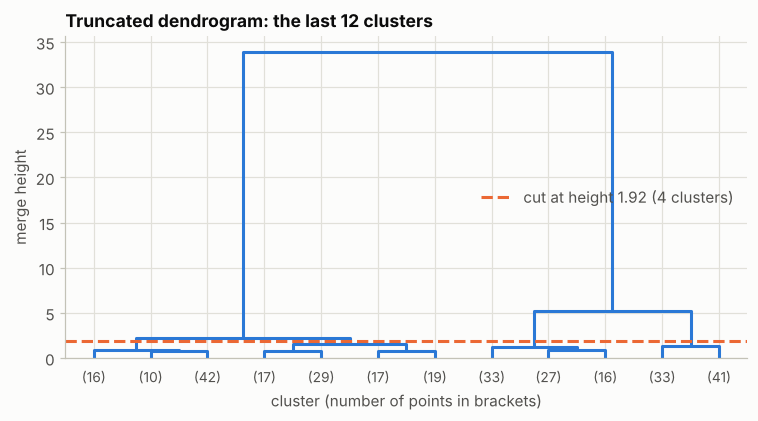

AgglomerativeClustering(n_clusters=None, distance_threshold=1.92) finds 4 clusters; same as n_clusters=4: True; same as SciPy's fcluster: True


In [19]:
# EXTRA: (b) the last merges of the Ward tree and the gaps between them
from scipy.cluster.hierarchy import fcluster

heights = linked[::-1, 2]                        # merge heights, the last merge first: heights[j] is the merge that leaves j + 1 clusters
rows = []
for K in range(2, 9):                            # K clusters exist for every cut between heights[K - 1] and heights[K - 2]
    rows.append({"K": K, "lowest cut": heights[K - 1], "highest cut": heights[K - 2],
                 "length of the stretch": heights[K - 2] - heights[K - 1], "ratio of the two": heights[K - 2] / heights[K - 1]})
print("range of cut heights that gives K clusters:")
print(pd.DataFrame(rows).set_index("K").round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
dendrogram(linked, truncate_mode="lastp", p=12, color_threshold=0, above_threshold_color=PALETTE[0], leaf_rotation=0, leaf_font_size=9, ax=ax)
cut = (linked[-4, 2] + linked[-3, 2]) / 2
ax.axhline(cut, color=PALETTE[1], linestyle="--", label=f"cut at height {cut:.2f} (4 clusters)")
ax.set_title("Truncated dendrogram: the last 12 clusters")
ax.set_xlabel("cluster (number of points in brackets)")
ax.set_ylabel("merge height")
ax.legend(loc="center right")
plt.show()

by_threshold = AgglomerativeClustering(n_clusters=None, distance_threshold=cut).fit(X)
print(f"AgglomerativeClustering(n_clusters=None, distance_threshold={cut:.2f}) finds {by_threshold.n_clusters_} clusters;",
      f"same as n_clusters=4: {adjusted_rand_score(by_threshold.labels_, y_agg) == 1.0}; same as SciPy's fcluster: {adjusted_rand_score(fcluster(linked, cut, criterion='distance'), y_agg) == 1.0}")

**(c) Four linkages on three shapes.** The book lists four linkages and shows only Ward. The cell applies all four to the three datasets of recipe 6 (isotropic blobs, moons, nested circles; the same generator calls as the book) with the true number of clusters, and reports the ARI with the generating labels.

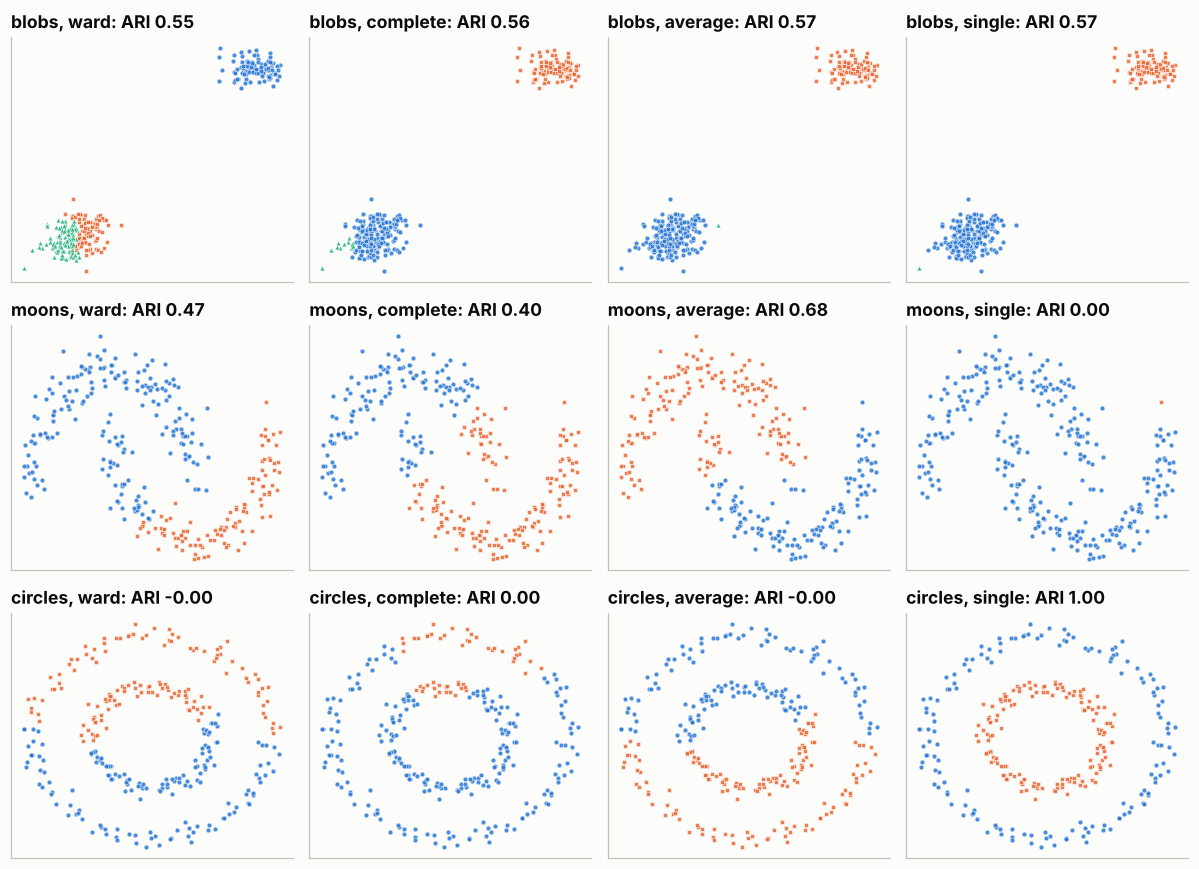

          ward  complete  average  single
blobs    0.552     0.562    0.569   0.569
moons    0.470     0.399    0.682   0.000
circles -0.003     0.003   -0.002   1.000

size of the largest cluster on the moons with single linkage: 299 of 300


In [20]:
# EXTRA: (c) four linkages on blobs, moons and circles
from sklearn.datasets import make_circles, make_moons

shapes = {}
Xb, yb = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)
Xm, ym = make_moons(n_samples=300, noise=0.1, random_state=2024)
Xc, yc = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)
shapes["blobs"] = (StandardScaler().fit_transform(Xb), yb, 3)
shapes["moons"] = (StandardScaler().fit_transform(Xm), ym, 2)
shapes["circles"] = (StandardScaler().fit_transform(Xc), yc, 2)

linkages = ["ward", "complete", "average", "single"]
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
rows = []
for r, (shape, (data, truth, k)) in enumerate(shapes.items()):
    scores = {}
    for c, name in enumerate(linkages):
        labels = AgglomerativeClustering(n_clusters=k, linkage=name).fit_predict(data)
        scores[name] = adjusted_rand_score(truth, labels)
        scatter_clusters(axes[r, c], data, labels, title=f"{shape}, {name}: ARI {scores[name]:.2f}", size=10)
    rows.append(pd.Series(scores, name=shape))
plt.tight_layout()
plt.show()
print(pd.DataFrame(rows).round(3).to_string())
print("\nsize of the largest cluster on the moons with single linkage:", np.bincount(AgglomerativeClustering(n_clusters=2, linkage="single").fit_predict(shapes["moons"][0])).max(), "of 300")

**(d) Divisive clustering exists: `BisectingKMeans`.** A hierarchy means that the partition into $K + 1$ clusters **refines** the one into $K$: every new cluster lies inside one old cluster. The cell tests this for $K = 2, \dots, 9$ on four datasets (the book's blobs, Iris, standardized Wine and the moons of recipe 4) for bisecting K-means, plain K-means and Ward, and counts the transitions $K \to K + 1$ (out of 7) that are nested.

In [21]:
# EXTRA: (d) BisectingKMeans is divisive: are the partitions for k = 2..9 nested?
from sklearn.cluster import BisectingKMeans
from sklearn.datasets import load_iris, load_wine


def refines(coarse, fine):
    """True if every cluster of `fine` lies inside a single cluster of `coarse`."""
    return all(len(set(coarse[fine == label])) == 1 for label in set(fine))


datasets = {"blobs (recipe 1)": X, "Iris": load_iris().data, "Wine (standardized)": StandardScaler().fit_transform(load_wine().data),
            "moons": StandardScaler().fit_transform(make_moons(n_samples=300, noise=0.1, random_state=2024)[0])}
methods = {"bisecting K-means": lambda k: BisectingKMeans(n_clusters=k, random_state=2024),
           "K-means": lambda k: KMeans(n_clusters=k, random_state=2024),
           "Ward": lambda k: AgglomerativeClustering(n_clusters=k)}
rows = []
for data_name, data in datasets.items():
    row = {"dataset": data_name}
    for method_name, make in methods.items():
        by_k = {k: make(k).fit_predict(data) for k in range(2, 10)}
        row[method_name] = sum(refines(by_k[k], by_k[k + 1]) for k in range(2, 9))
    rows.append(row)
print("number of nested transitions k -> k+1, out of 7:")
print(pd.DataFrame(rows).set_index("dataset").to_string())
print(f"\nbisecting K-means with k=4 on the blobs: ARI with the true blobs {adjusted_rand_score(y_true, BisectingKMeans(n_clusters=4, random_state=2024).fit_predict(X)):.3f} (K-means: {adjusted_rand_score(y_true, y_kmeans):.3f})")

number of nested transitions k -> k+1, out of 7:
                     bisecting K-means  K-means  Ward
dataset                                              
blobs (recipe 1)                     7        3     7
Iris                                 7        1     7
Wine (standardized)                  7        0     7
moons                                7        0     7

bisecting K-means with k=4 on the blobs: ARI with the true blobs 0.795 (K-means: 0.801)


**Analysis of the extras.**

* **(a)** The 29 merges of the by-hand Ward method have the same heights as SciPy's, and the cost used for each merge is exactly the increase of the sum of squares. Ward's method really is "minimize the variance of the merged clusters".
* **(b)** The stretch of cut heights that gives $K$ clusters is 28.74 long for $K = 2$ (a ratio of 6.5 between its ends), 2.95 for $K = 3$ (ratio 2.3), but only 0.68 for $K = 4$ (ratio 1.4), 0.29 for $K = 5$ and 0.03 for $K = 6$. The dendrogram prefers 2, and 3 is a distinct second; 4 is not singled out. Cutting at height 1.92, in the middle of the stretch for $K = 4$, gives 4 clusters, identical for `distance_threshold`, for `n_clusters=4` and for SciPy's `fcluster`.
* **(c)** No linkage is best everywhere. On the **blobs** all four score between 0.55 and 0.57. On the **moons**, average linkage is the best (0.682), Ward 0.470, complete 0.399, and **single linkage 0.000**: it isolates one outlier and puts the other 299 points in one cluster, chaining the two moons through the noise. On the **circles** only single linkage works (**1.000**); the other three are at 0. The book's default, Ward, prefers compact clusters and fails on both curved shapes.
* **(d)** Bisecting K-means and Ward give nested partitions for $K = 2, \dots, 9$ on every dataset (7 transitions out of 7). Plain K-means does not: 3 of 7 on the blobs, 1 on Iris, 0 on Wine and 0 on the moons. So `BisectingKMeans` is a divisive hierarchical method, which contradicts the book's statement. It costs little accuracy on the blobs (ARI 0.795 against 0.801).

---
## 4. Density-based clustering with DBSCAN

### Summary

* **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) finds "clusters of varying shapes and sizes". Unlike K-means and hierarchical clustering it does not need the number of clusters and it handles outliers (noise). It "does not generate centroids a priori".
* **Getting ready** — `make_moons(n_samples=300, noise=0.1, random_state=2024)`: two crescents, a shape for which K-means "would fail at providing an optimal clustering solution".
* **How to do it** — `DBSCAN(eps=0.2, min_samples=5)` and a scatter plot (Figure 10.6); noise points are labelled -1.
* **How it works** — `eps` is the radius of the neighbourhood of a point and `min_samples` is the number of points that make a region dense. **Core points** have at least `min_samples` points within `eps`; **border points** are within `eps` of a core point but are not core themselves; **noise points** are neither. The algorithm starts from an unvisited point and "forms clusters by recursively including density-connected neighbors".
* **There's more** — choosing the parameters: "plot the distance to the k-th nearest neighbor (where k = min_samples) for all points and look for a sharp bend (elbow)". The listing uses `NearestNeighbors(n_neighbors=5)` and plots the sorted fifth column (Figure 10.7).
* **Hands-on exercises** — six steps: a noisy dataset, `DBSCAN`, identify the noise points, a k-distance plot, and combinations of `eps` and `min_samples`.

### Theory: density-reachability, and why one `eps` is a strong assumption

**Definitions** (Ester et al., 1996). The $\varepsilon$-neighbourhood of a point $p$ is $N_\varepsilon(p) = \{ q : d(p, q) \le \varepsilon \}$; it **contains $p$ itself**. With the parameter $m$ = `min_samples`:

* $p$ is a **core point** if $\lvert N_\varepsilon(p) \rvert \ge m$;
* $q$ is **directly density-reachable** from $p$ if $p$ is a core point and $q \in N_\varepsilon(p)$;
* $q$ is **density-reachable** from $p$ if there is a chain of points, each directly density-reachable from the previous one, from $p$ to $q$; the chain passes only through core points, except possibly its last point;
* two points are **density-connected** if some point reaches both;
* a **cluster** is a maximal set of density-connected points; a **border point** belongs to a cluster without being core; **noise** is every other point.

**Algorithm.** Visit the points in turn. A non-core point is provisionally noise. A core point starts a cluster, which grows by a breadth-first search over the neighbourhoods of its core points. With a spatial index (k-d tree, ball tree) the cost is about $O(n \log n)$. The result is deterministic except for **border points** that are reachable from two clusters: they join the first one that reaches them.

**Choosing the parameters.**

* `min_samples`: a minimum of $d + 1$ (Ester et al.), often $2d$ (Sander et al., 1998), and larger for noisy data. Larger values make the clusters more conservative and label more points as noise.
* `eps`: the **k-distance plot**. If the distance to the $m$-th neighbour of a point is $\le \varepsilon$, the point is a core point. Sorting those distances shows what share of the points would be core for each $\varepsilon$; the bend of the curve is where noise starts. Because a point is its own first neighbour, the $m$-th neighbour *including the point* is the $(m-1)$-th *other* point. The extras verify this.

**Limits.**

* **One density.** A single `eps` describes one density level. If one cluster is dense and another is sparse, a small `eps` shatters the sparse one into pieces and noise, and a large one merges the dense one with its surroundings. `OPTICS` (Ankerst et al., 1999) and `HDBSCAN` (Campello et al., 2013; in scikit-learn since 1.3) build a hierarchy over all values of `eps` and extract the clusters that persist.
* **Scale.** `eps` is a distance, so the features must be on comparable scales.
* **No `predict`.** DBSCAN labels the data it was fitted on; there is no model for new points (`fit_predict` only).
* **High dimensions.** Distances concentrate, and a density threshold loses its meaning (see recipe 6).

**A link to hierarchical clustering.** With `min_samples=1` every point is core, and the clusters are the connected components of the graph that joins points closer than `eps`. These are exactly the clusters obtained by cutting the **single-linkage** dendrogram at height `eps`. The extras check it.

### Book code (pp. 264–267)

In [22]:
# BOOK CODE (p. 264): load the libraries and create the moons dataset
# Load the libraries
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

# Create a new one with noise
X, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)

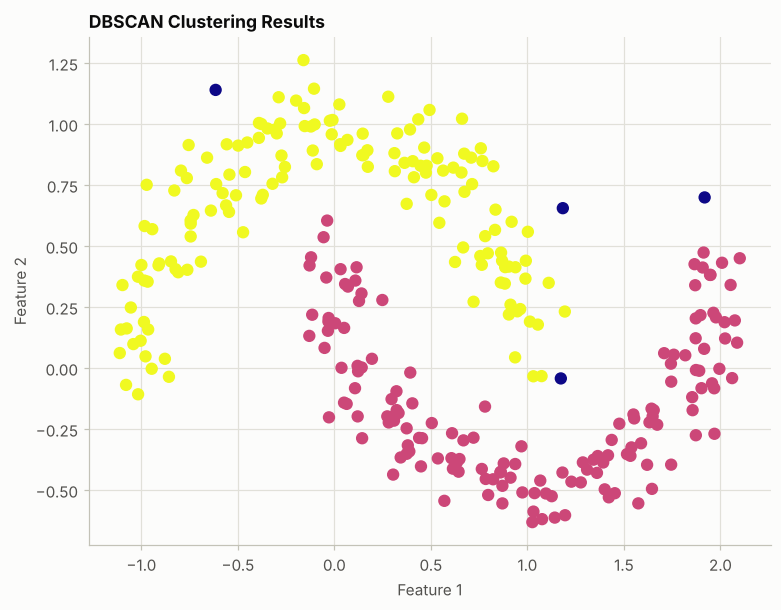

In [23]:
# BOOK CODE (pp. 264-265): apply DBSCAN and plot the result
# Apply DBSCAN
dbscan = DBSCAN(eps=0.2, min_samples=5)
y_db = dbscan.fit_predict(X)

# Plot the DBSCAN results
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_db, cmap='plasma', s=50)
plt.title("DBSCAN Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

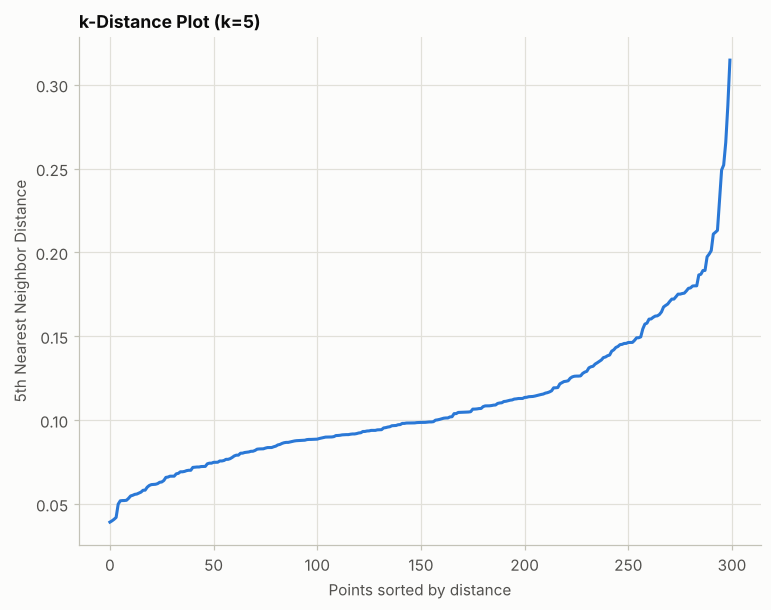

In [24]:
# BOOK CODE (pp. 266-267): the k-distance plot
# Load libraries
from sklearn.neighbors import NearestNeighbors

# Generate Nearest Neighbors
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, 4])

# Plot k-distance
plt.figure(figsize=(8, 6))
plt.plot(distances)
plt.title("k-Distance Plot (k=5)")
plt.xlabel("Points sorted by distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.show()

In [25]:
# EXTRA: inspect what the book's code produced
_, ym = make_moons(n_samples=300, noise=0.1, random_state=2024)     # the true moon of each point, which the book discards
clusters, sizes = np.unique(y_db, return_counts=True)
print(f"DBSCAN found {int((clusters >= 0).sum())} clusters of sizes {sizes[clusters >= 0].tolist()} and {int(sizes[clusters == -1].sum()) if -1 in clusters else 0} noise points (label -1)")
print(f"agreement with the two moons: ARI {adjusted_rand_score(ym, y_db):.3f}")
print(f"core points: {len(dbscan.core_sample_indices_)} of {len(X)}; the model has no predict method: {not hasattr(dbscan, 'predict')}")
print(f"k-distance plot: the sorted values go from {distances[0]:.3f} to {distances[-1]:.3f}; {np.mean(distances <= 0.2):.1%} of the points are at most 0.2 from their 5th neighbour")

DBSCAN found 2 clusters of sizes [150, 146] and 4 noise points (label -1)
agreement with the two moons: ARI 0.960
core points: 290 of 300; the model has no predict method: True
k-distance plot: the sorted values go from 0.039 to 0.315; 96.7% of the points are at most 0.2 from their 5th neighbour


**Output analysis.**

* With `eps=0.2` and `min_samples=5`, DBSCAN finds **2 clusters** of 150 and 146 points and **4 noise points**. The ARI with the true moons is 0.960 (the noise points count as an extra group). The picture shows the two crescents; the few points labelled -1 get a colour of their own.
* **290 of the 300 points are core points**; the model has no `predict` method.
* The k-distance values go from 0.039 to 0.315, and 96.7% of the points are at most 0.2 from their fifth neighbour. This share is exactly the share of core points (290 of 300), which the extras explain.

### Extra: experiments for recipe 4

**(a) Core, border and noise.** The three kinds of points of the book's result, drawn separately.

core points: 290, border points: 6, noise points: 4 (total 300)
border points per cluster: {0: 2, 1: 4}


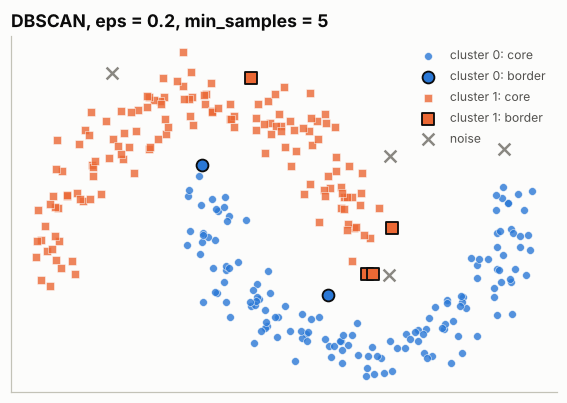

In [26]:
# EXTRA: (a) core, border and noise points of the book's DBSCAN
is_core = np.zeros(len(X), dtype=bool)
is_core[dbscan.core_sample_indices_] = True
is_noise = y_db == -1
is_border = ~is_core & ~is_noise
print(f"core points: {is_core.sum()}, border points: {is_border.sum()}, noise points: {is_noise.sum()} (total {len(X)})")
print("border points per cluster:", {int(c): int((is_border & (y_db == c)).sum()) for c in sorted(set(y_db)) if c != -1})

fig, ax = plt.subplots(figsize=(6.4, 4.2))
for cluster in sorted(set(y_db) - {-1}):
    ax.scatter(*X[is_core & (y_db == cluster)].T, c=PALETTE[cluster % 3], marker=MARKERS[cluster], s=26, alpha=0.8, edgecolors=SURFACE, linewidths=0.4, label=f"cluster {cluster}: core")
    ax.scatter(*X[is_border & (y_db == cluster)].T, c=PALETTE[cluster % 3], marker=MARKERS[cluster], s=60, edgecolors=INK, linewidths=1.2, label=f"cluster {cluster}: border")
ax.scatter(*X[is_noise].T, c=MUTED, marker="x", s=60, linewidths=1.6, label="noise")
ax.set_title("DBSCAN, eps = 0.2, min_samples = 5")
ax.legend(loc="upper right", fontsize=8, ncol=1)
ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
plt.show()

**(b) The k-distance plot, decoded.** `kneighbors(X)` on the training data returns the point itself as its own nearest neighbour, at distance 0. So column 4 (the fifth) is the distance to the **fourth other** point, which is the distance within which the point has 5 points, itself included: exactly what `min_samples=5` counts. The cell verifies that the points of the plot that lie under `eps` are the core points of the model, and marks the bend with a simple rule (the point farthest from the straight line between the first and the last value of the curve).

the first column of kneighbors is the point itself (distance 0): True
points whose 5th neighbour (itself included) is within 0.2: 290; core points of DBSCAN(eps=0.2, min_samples=5): 290; same points: True
the bend of the curve is at point 256 of 300, at a distance of 0.150


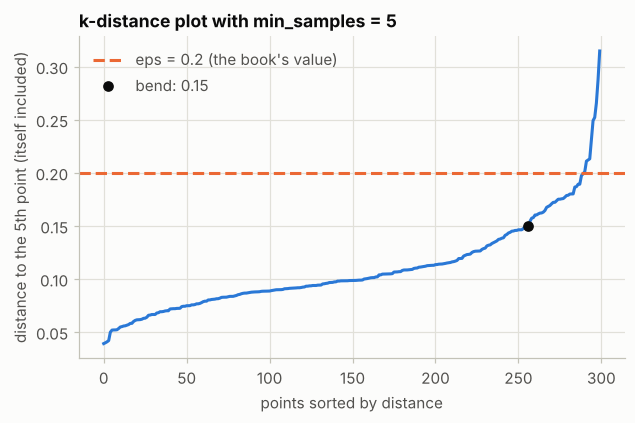

In [27]:
# EXTRA: (b) the k-distance plot and the core points
print("the first column of kneighbors is the point itself (distance 0):", bool((neighbors_fit.kneighbors(X)[0][:, 0] == 0).all()))
core_from_plot = np.flatnonzero(neighbors_fit.kneighbors(X)[0][:, 4] <= 0.2)
print(f"points whose 5th neighbour (itself included) is within 0.2: {len(core_from_plot)}; core points of DBSCAN(eps=0.2, min_samples=5): {len(dbscan.core_sample_indices_)}; same points: {set(core_from_plot) == set(dbscan.core_sample_indices_)}")

# the bend: the point of the curve farthest from the chord between its ends
positions = np.arange(len(distances))
chord = distances[0] + (distances[-1] - distances[0]) * positions / (len(distances) - 1)
bend = int(np.argmax(chord - distances))
print(f"the bend of the curve is at point {bend} of {len(distances)}, at a distance of {distances[bend]:.3f}")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(positions, distances, color=PALETTE[0])
ax.axhline(0.2, color=PALETTE[1], linestyle="--", label="eps = 0.2 (the book's value)")
ax.plot(bend, distances[bend], "o", color=INK, label=f"bend: {distances[bend]:.2f}")
ax.set_xlabel("points sorted by distance")
ax.set_ylabel("distance to the 5th point (itself included)")
ax.set_title("k-distance plot with min_samples = 5")
ax.legend(loc="upper left")
plt.show()

**(c) How wide is the window of `eps`?** The ARI with the true moons for a grid of `eps` and `min_samples` (white cells have an ARI of 0 or below), and the number of clusters found.

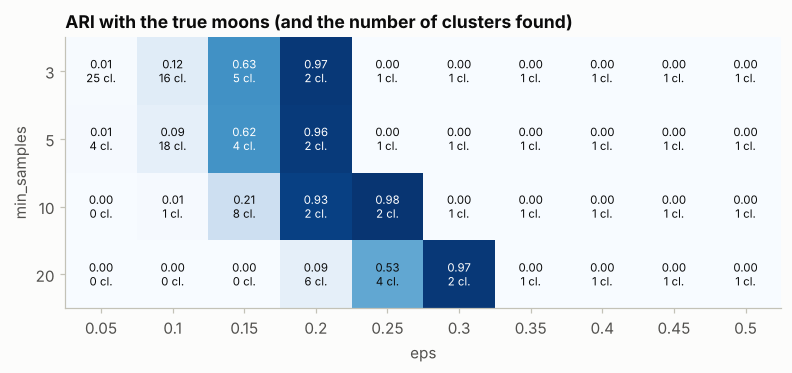

settings with ARI above 0.9: {3: [0.2], 5: [0.2], 10: [0.2, 0.25], 20: [0.3]}


In [28]:
# EXTRA: (c) ARI with the true moons over a grid of eps and min_samples
eps_grid = np.round(np.arange(0.05, 0.51, 0.05), 2)
min_samples_grid = [3, 5, 10, 20]
ari_grid = np.zeros((len(min_samples_grid), len(eps_grid)))
n_clusters_grid = np.zeros_like(ari_grid, dtype=int)
for i, m in enumerate(min_samples_grid):
    for j, e in enumerate(eps_grid):
        labels = DBSCAN(eps=e, min_samples=m).fit_predict(X)
        ari_grid[i, j] = adjusted_rand_score(ym, labels)
        n_clusters_grid[i, j] = len(set(labels)) - (1 if -1 in labels else 0)

fig, ax = plt.subplots(figsize=(8.4, 3.2))
image = ax.imshow(np.clip(ari_grid, 0, 1), cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(len(min_samples_grid)):
    for j in range(len(eps_grid)):
        ax.text(j, i, f"{ari_grid[i, j]:.2f}\n{n_clusters_grid[i, j]} cl.", ha="center", va="center", fontsize=7.5,
                color="white" if ari_grid[i, j] > 0.6 else INK)
ax.set_xticks(range(len(eps_grid)))
ax.set_xticklabels(eps_grid)
ax.set_yticks(range(len(min_samples_grid)))
ax.set_yticklabels(min_samples_grid)
ax.set_xlabel("eps")
ax.set_ylabel("min_samples")
ax.set_title("ARI with the true moons (and the number of clusters found)")
ax.grid(False)
plt.show()
good = ari_grid > 0.9
print("settings with ARI above 0.9:", {m: [float(e) for e in eps_grid[good[i]]] for i, m in enumerate(min_samples_grid)})

**(d) DBSCAN with `min_samples=1` is single linkage.** With `min_samples=1` every point is core, so DBSCAN returns the connected components of the `eps`-graph, the clusters of the single-linkage tree cut at height `eps`.

In [29]:
# EXTRA: (d) DBSCAN(min_samples=1) equals a single-linkage cut at height eps
single = linkage(X, method="single")
for eps in (0.1, 0.15, 0.2):
    labels_db = DBSCAN(eps=eps, min_samples=1).fit_predict(X)
    labels_single = fcluster(single, t=eps, criterion="distance")
    print(f"eps = {eps}: DBSCAN finds {len(set(labels_db))} clusters, single linkage finds {len(set(labels_single))}; identical partitions: {adjusted_rand_score(labels_db, labels_single) == 1.0}")

eps = 0.1: DBSCAN finds 44 clusters, single linkage finds 44; identical partitions: True
eps = 0.15: DBSCAN finds 10 clusters, single linkage finds 10; identical partitions: True
eps = 0.2: DBSCAN finds 5 clusters, single linkage finds 5; identical partitions: True


**(e) Clusters of different density.** Three blobs with standard deviations 1.0, 2.5 and 0.5 (the second dataset of recipe 2), standardized. DBSCAN is run for three values of `eps` and compared with `HDBSCAN`, which needs no `eps`, only a minimum cluster size.

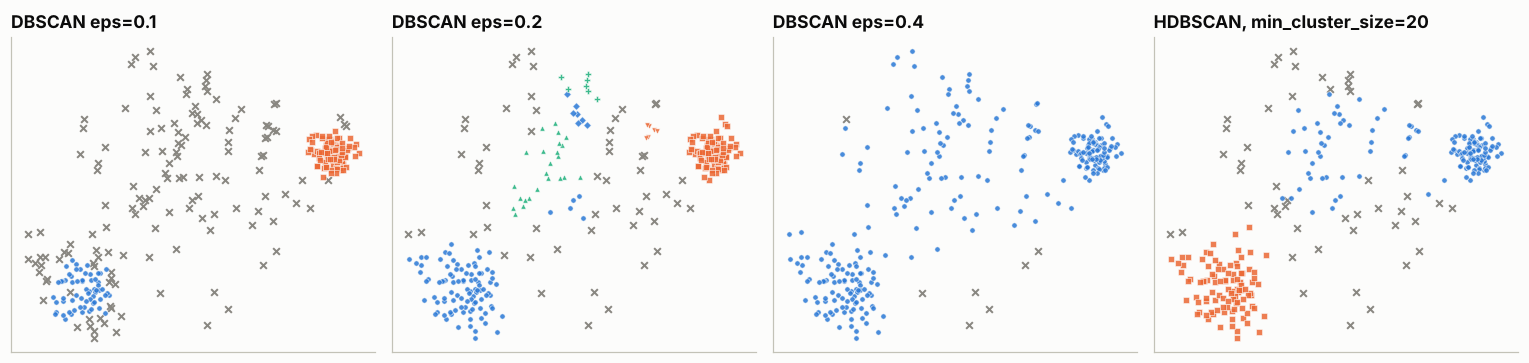

                              clusters  noise points  ARI with the true blobs
model                                                                        
DBSCAN eps=0.1                       2           139                    0.649
DBSCAN eps=0.2                       7            52                    0.768
DBSCAN eps=0.4                       1             7                    0.002
HDBSCAN, min_cluster_size=20         2            49                    0.606


In [30]:
# EXTRA: (e) one eps cannot suit three densities; HDBSCAN
from sklearn.cluster import HDBSCAN

dense_sparse = StandardScaler().fit_transform(unequal_spread)
candidates = {f"DBSCAN eps={e}": DBSCAN(eps=e, min_samples=5) for e in (0.1, 0.2, 0.4)}
warnings.filterwarnings("ignore", message="The default value of `copy`")   # a FutureWarning about HDBSCAN(copy=...)
candidates["HDBSCAN, min_cluster_size=20"] = HDBSCAN(min_cluster_size=20)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
rows = []
for ax, (name, model) in zip(axes, candidates.items()):
    labels = model.fit_predict(dense_sparse)
    n_found = len(set(labels)) - (1 if -1 in labels else 0)
    rows.append({"model": name, "clusters": n_found, "noise points": int((labels == -1).sum()), "ARI with the true blobs": adjusted_rand_score(y_spread, labels)})
    scatter_clusters(ax, dense_sparse, labels, title=name, size=12)
plt.tight_layout()
plt.show()
print(pd.DataFrame(rows).set_index("model").round(3).to_string())

**Analysis of the extras.**

* **(a)** Of the 300 points, 290 are core, **6 are border** points (2 in cluster 0 and 4 in cluster 1) and 4 are noise. A border point belongs to a cluster but could not have started one.
* **(b)** The first column of `kneighbors` is the point itself at distance 0. So the book's "5th nearest neighbour" is the **fourth other point**, which is what `min_samples=5` counts (the point included). The 290 points under the line `eps = 0.2` of the plot are exactly the 290 core points of the model. The bend of the curve, by the chord rule, is at 0.150, **below** the working value: with `eps=0.15` the moons break into 4 clusters (the grid below, ARI 0.62). The bend marks where noise starts; a usable `eps` is a little above it. The plot gives a first guess, not the answer.
* **(c)** The window is narrow. With `min_samples=5` only `eps=0.2` of the grid scores an ARI above 0.9 (0.96); 0.15 gives 4 clusters (0.62) and 0.25 merges everything into one cluster (0.00). With `min_samples=3` the window is again 0.2 alone, with 10 it is 0.2 and 0.25, with 20 it is 0.3. A larger `min_samples` needs a larger `eps`, and one grid step (a factor 1.25 in `eps`) is enough to leave the window.
* **(d)** With `min_samples=1` DBSCAN returns exactly the clusters of the single-linkage tree cut at height `eps` (44, 10 and 5 clusters for 0.1, 0.15 and 0.2, identical partitions). DBSCAN adds the density requirement (`min_samples > 1`) that stops chaining through thin bridges.
* **(e)** For three blobs of different spread there is no good `eps`. At 0.1 only the two denser blobs are found and **139 points (46%)** are noise (ARI 0.649); at 0.2 the loose blob is shattered into pieces (7 clusters, 52 noise points, ARI 0.768, the best of the three); at 0.4 everything merges into one cluster (ARI 0.002). `HDBSCAN`, which needs no `eps`, returns 2 clusters and 49 noise points (ARI 0.606): fewer pieces than `eps=0.2` and fewer noise points than `eps=0.1`, but its ARI is lower than both, so it is not a cure.

---
## 5. Cluster evaluation metrics

### Summary

* Evaluating a clustering is "crucial", but "unlike supervised learning, clustering lacks true labels or target values", so the book relies on **internal** metrics (the **silhouette score** and the **Davies-Bouldin index**) and on an **external** one when the truth is known (the **adjusted Rand index**). Evaluation "can be seen as more of an art than a science".
* **Getting ready** — import the three metrics, generate the blobs of recipe 1 **without scaling and with their true labels** (`X, y_true = make_blobs(...)`), and fit `KMeans(n_clusters=4)`.
* **How to do it** — print the three scores. The book shows the output: silhouette 0.534, Davies-Bouldin 0.702, adjusted Rand index 0.814.
* **How it works** — the **silhouette** "measures how similar a point is to its own cluster compared to other clusters", from -1 to 1, higher is better. The **Davies-Bouldin index** averages, over the clusters, the similarity to the most similar other cluster; lower is better, and "unlike the silhouette score, this metric penalizes overlapping clusters". The **ARI** compares the clustering with a ground truth "by examining all pairs of samples and counting pairs assigned to the same or different clusters", corrects for chance, and ranges from -1 to 1.
* **There's more** — the **Calinski-Harabasz index** (variance ratio criterion) "favors well-separated and dense clusters".
* **Hands-on exercises** — six steps, including varying the number of clusters and watching how the metrics respond.

### Theory: internal and external metrics

**Silhouette** (Rousseeuw, 1987). For a sample $i$ in cluster $C_I$, let $a(i)$ be its mean distance to the other members of its own cluster, and $b(i)$ its mean distance to the members of the **nearest other cluster**:

$$
a(i) = \frac{1}{\lvert C_I \rvert - 1} \sum_{j \in C_I,\, j \ne i} d(i, j), \qquad
b(i) = \min_{J \ne I} \frac{1}{\lvert C_J \rvert} \sum_{j \in C_J} d(i, j), \qquad
s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}} .
$$

$s(i)$ is close to 1 if the sample is much nearer to its own cluster than to any other, 0 if it lies between two clusters, and negative if it is probably in the wrong cluster. The silhouette score is the mean of $s(i)$. A common reading (Kaufman and Rousseeuw, 1990) is: above 0.7 strong structure, 0.5 to 0.7 reasonable, 0.25 to 0.5 weak, below 0.25 no substantial structure. It needs all pairwise distances, $O(n^2)$.

**Davies-Bouldin index** (1979). With $s_i$ the mean distance of the points of cluster $i$ to its centroid $\boldsymbol{\mu}_i$:

$$
\text{DB} = \frac{1}{K} \sum_{i=1}^{K} \max_{j \ne i} \frac{s_i + s_j}{\lVert \boldsymbol{\mu}_i - \boldsymbol{\mu}_j \rVert} .
$$

It is the average ratio of within-cluster scatter to between-cluster separation for each cluster's worst neighbour. It is $\ge 0$ and **lower is better**.

**Calinski-Harabasz index** (1974). With $B$ the between-cluster and $W$ the within-cluster scatter matrices:

$$
\text{CH} = \frac{\operatorname{tr}(B) / (K - 1)}{\operatorname{tr}(W) / (n - K)} .
$$

It is the ratio of the between-cluster to the within-cluster variance, each divided by its degrees of freedom. **Higher is better**, and it is cheap, $O(nd)$.

All three are **internal**: they use only the data and the labels, and they reward **compact, convex, well-separated** clusters. They are not neutral: an algorithm that optimizes compactness (K-means) is judged by metrics that measure compactness. They also keep no memory of the number of clusters: the silhouette and CH can be compared across $K$, DB too, but none of them says that a given $K$ is "correct".

**Adjusted Rand index** (Hubert and Arabie, 1985) is **external**: it compares two partitions of the same samples. The **Rand index** is the share of the $\binom{n}{2}$ pairs of samples on which the partitions agree (both together, or both apart). Chance makes it high even for random labels, so the ARI subtracts the value expected for random partitions with the same cluster sizes. With the contingency table of the two partitions ($n_{ij}$ = samples in cluster $i$ of the first and cluster $j$ of the second; $a_i$ and $b_j$ the row and column sums):

$$
\text{ARI} = \frac{\sum_{ij} \binom{n_{ij}}{2} - \Big[\sum_i \binom{a_i}{2} \sum_j \binom{b_j}{2}\Big] \Big/ \binom{n}{2}}
{\tfrac{1}{2} \Big[\sum_i \binom{a_i}{2} + \sum_j \binom{b_j}{2}\Big] - \Big[\sum_i \binom{a_i}{2} \sum_j \binom{b_j}{2}\Big] \Big/ \binom{n}{2}} .
$$

It is 1 for identical partitions, close to 0 for independent ones, and can be slightly negative. It **ignores the names of the clusters** (a permutation of the labels changes nothing). Related external scores: normalized mutual information, homogeneity, completeness and V-measure, and the Fowlkes-Mallows index. An external score measures agreement with *one* labelling; the data may have several valid ones.

### Book code (pp. 268–270)

In [31]:
# BOOK CODE (p. 268): load the libraries, generate the labelled blobs (not scaled) and fit K-means
# Load the libraries
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Generate a labeled dataset for evaluation
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)

# Fit KMeans for use with evaluation metrics
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

In [32]:
# BOOK CODE (p. 269): the three metrics
# Calculate the silhouette score
sil_score = silhouette_score(X, y_kmeans)
print(f"Silhouette Score: {sil_score:.3f}")

# Calculate the Davies-Bouldin index
db_index = davies_bouldin_score(X, y_kmeans)
print(f"Davies-Bouldin Index: {db_index:.3f}")

# (Optional) Calculate adjusted Rand index if ground truth is known
ari = adjusted_rand_score(y_true, y_kmeans)
print(f"Adjusted Rand Index: {ari:.3f}")

Silhouette Score: 0.534
Davies-Bouldin Index: 0.702
Adjusted Rand Index: 0.814


**Output analysis.**

* The three scores **reproduce the book's printed output exactly**: silhouette 0.534, Davies-Bouldin index 0.702, adjusted Rand index 0.814.
* They are computed on the **unscaled** blobs (this recipe generates its own data, without `StandardScaler`). On the standardized data of recipe 1, the same model gives a silhouette of 0.531 and an ARI of 0.801.
* A silhouette of 0.534 is "reasonable" by the usual reading (0.5 to 0.7), a Davies-Bouldin index below 1 is acceptable, and an ARI of 0.814 is a high but imperfect agreement: extra (a) shows which points are wrong.

### Extra: experiments for recipe 5

**(a) The metrics by hand.** The three internal metrics and the ARI recomputed from their definitions with NumPy. Each value must equal the library's. The figure is the classic **silhouette plot**: the $s(i)$ of every sample, grouped by cluster and sorted, so that the clusters with weakly assigned samples (short or negative bars) are visible.

metric                       by hand  scikit-learn
silhouette                    0.5343        0.5343   equal: True
Davies-Bouldin                0.7017        0.7017   equal: True
Calinski-Harabasz          8670.7791     8670.7791   equal: True
adjusted Rand index           0.8138        0.8138   equal: True

contingency table (rows: true blobs, columns: K-means clusters):
    0   1   2   3
0   0  75   0   0
1   9   0   0  66
2  62   0   0  13
3   0   2  73   0

mean silhouette per K-means cluster: {0: 0.395, 1: 0.628, 2: 0.639, 3: 0.471} | samples with a negative silhouette: 2


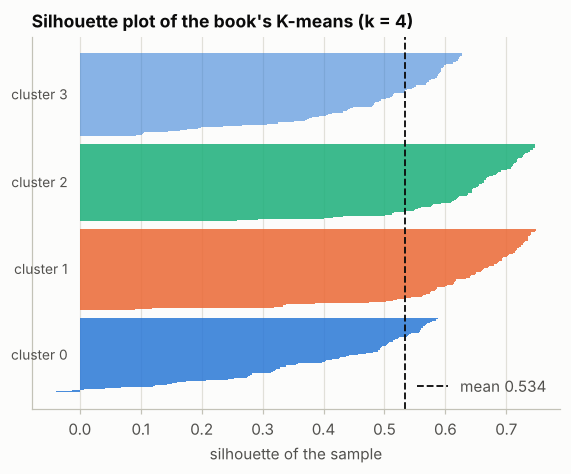

In [33]:
# EXTRA: (a) silhouette, Davies-Bouldin, Calinski-Harabasz and ARI recomputed from their definitions
from math import comb

from scipy.spatial.distance import cdist, pdist, squareform
from sklearn.metrics import calinski_harabasz_score, silhouette_samples

labels = y_kmeans
n, K = len(X), 4
D = squareform(pdist(X))

s = np.zeros(n)
for i in range(n):
    own = labels == labels[i]
    own[i] = False
    a = D[i, own].mean()
    b = min(D[i, labels == other].mean() for other in set(labels) if other != labels[i])
    s[i] = (b - a) / max(a, b)

centres = np.array([X[labels == k].mean(axis=0) for k in range(K)])
scatter = np.array([np.linalg.norm(X[labels == k] - centres[k], axis=1).mean() for k in range(K)])
separation = cdist(centres, centres)
db = np.mean([max((scatter[i] + scatter[j]) / separation[i, j] for j in range(K) if j != i) for i in range(K)])

grand = X.mean(axis=0)
between = sum((labels == k).sum() * ((centres[k] - grand) ** 2).sum() for k in range(K))
within = sum(((X[labels == k] - centres[k]) ** 2).sum() for k in range(K))
ch = (between / (K - 1)) / (within / (n - K))

table = np.zeros((K, K), dtype=int)
for truth, found in zip(y_true, labels):
    table[truth, found] += 1
pairs = lambda counts: sum(comb(int(c), 2) for c in np.ravel(counts))
expected = pairs(table.sum(axis=1)) * pairs(table.sum(axis=0)) / comb(n, 2)
ari_by_hand = (pairs(table) - expected) / ((pairs(table.sum(axis=1)) + pairs(table.sum(axis=0))) / 2 - expected)

print(f"{'metric':26s}{'by hand':>10s}{'scikit-learn':>14s}")
for name, mine, library in [("silhouette", s.mean(), silhouette_score(X, labels)), ("Davies-Bouldin", db, davies_bouldin_score(X, labels)),
                            ("Calinski-Harabasz", ch, calinski_harabasz_score(X, labels)), ("adjusted Rand index", ari_by_hand, adjusted_rand_score(y_true, labels))]:
    print(f"{name:26s}{mine:10.4f}{library:14.4f}   equal: {np.isclose(mine, library)}")
print("\ncontingency table (rows: true blobs, columns: K-means clusters):")
print(pd.DataFrame(table).to_string())
print("\nmean silhouette per K-means cluster:", {k: round(float(s[labels == k].mean()), 3) for k in range(K)}, "| samples with a negative silhouette:", int((s < 0).sum()))

fig, ax = plt.subplots(figsize=(6.2, 4.4))
position = 0
for k in range(K):
    values = np.sort(silhouette_samples(X, labels)[labels == k])
    ax.barh(range(position, position + len(values)), values, height=1.0, color=PALETTE[k % 3], alpha=0.85 if k < 3 else 0.55)
    ax.text(-0.02, position + len(values) / 2, f"cluster {k}", ha="right", va="center", color=INK_SOFT, fontsize=9)
    position += len(values) + 8
ax.axvline(s.mean(), color=INK, linestyle="--", linewidth=1.2, label=f"mean {s.mean():.3f}")
ax.set_yticks([])
ax.set_xlabel("silhouette of the sample")
ax.set_title("Silhouette plot of the book's K-means (k = 4)")
ax.legend(loc="lower right")
plt.show()

**(b) The metrics against the number of clusters.** K-means with $k = 2, \dots, 8$ on the same data. The silhouette and CH should be high and DB low at the best $k$; the ARI shows what the generator really contains (4 blobs).

   silhouette (max)  Davies-Bouldin (min)  Calinski-Harabasz (max)  ARI with the true blobs (max)
k                                                                                                
2             0.887                 0.169                 8523.616                          0.497
3             0.768                 0.390                 8819.986                          0.697
4             0.534                 0.702                 8670.779                          0.814
5             0.446                 0.879                 7294.189                          0.729
6             0.391                 0.966                 6461.760                          0.633
7             0.400                 0.942                 6172.063                          0.581
8             0.413                 0.884                 5728.607                          0.574

best k for each metric: {'silhouette': 2, 'Davies-Bouldin': 2, 'Calinski-Harabasz': 3, 'ARI with the true blobs': 4}


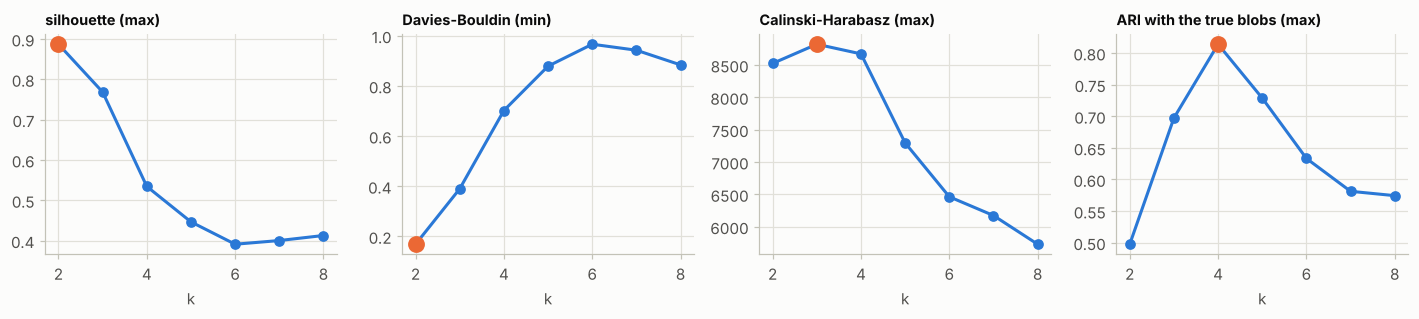

In [34]:
# EXTRA: (b) the three internal metrics and the ARI for k = 2..8
rows = []
for k in range(2, 9):
    labels_k = KMeans(n_clusters=k, random_state=2024).fit_predict(X)
    rows.append({"k": k, "silhouette (max)": silhouette_score(X, labels_k), "Davies-Bouldin (min)": davies_bouldin_score(X, labels_k),
                 "Calinski-Harabasz (max)": calinski_harabasz_score(X, labels_k), "ARI with the true blobs (max)": adjusted_rand_score(y_true, labels_k)})
by_k = pd.DataFrame(rows).set_index("k")
print(by_k.round(3).to_string())
print("\nbest k for each metric:", {name.split(" (")[0]: int(by_k[name].idxmin() if "min" in name else by_k[name].idxmax()) for name in by_k.columns})

fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, name in zip(axes, by_k.columns):
    ax.plot(by_k.index, by_k[name], "o-", color=PALETTE[0])
    best_k = by_k[name].idxmin() if "min" in name else by_k[name].idxmax()
    ax.plot(best_k, by_k.loc[best_k, name], "o", color=PALETTE[1], markersize=10)
    ax.set_title(name, fontsize=9.5)
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()

**(c) Internal metrics on curved clusters.** The scaled moons of the exercises, with three clusterings: the **true** moons, K-means with $k = 2$ and DBSCAN (`eps=0.3`). The noise points of DBSCAN are left out of its internal scores. If the internal metrics measured the quality of a clustering in general, the true moons would win.

                  silhouette  Davies-Bouldin  Calinski-Harabasz  ARI with the truth
clustering                                                                         
true moons             0.377           1.036            247.362               1.000
K-means (k=2)          0.485           0.820            396.343               0.507
DBSCAN (eps=0.3)       0.402           0.981            269.606               0.948


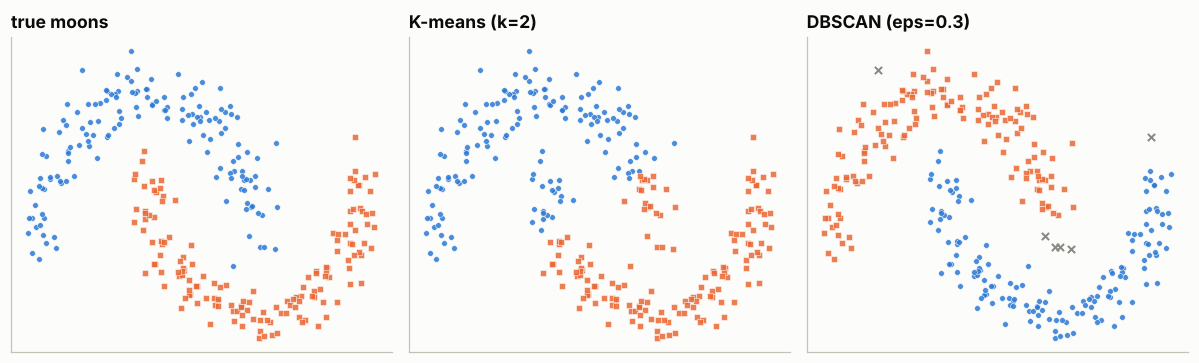

In [35]:
# EXTRA: (c) internal metrics versus ARI on the moons
Xm, ym = make_moons(n_samples=300, noise=0.1, random_state=2024)
Xm = StandardScaler().fit_transform(Xm)
clusterings = {"true moons": ym,
               "K-means (k=2)": KMeans(n_clusters=2, random_state=2024).fit_predict(Xm),
               "DBSCAN (eps=0.3)": DBSCAN(eps=0.3, min_samples=5).fit_predict(Xm)}
rows = []
for name, labels_m in clusterings.items():
    keep = labels_m != -1
    rows.append({"clustering": name, "silhouette": silhouette_score(Xm[keep], labels_m[keep]), "Davies-Bouldin": davies_bouldin_score(Xm[keep], labels_m[keep]),
                 "Calinski-Harabasz": calinski_harabasz_score(Xm[keep], labels_m[keep]), "ARI with the truth": adjusted_rand_score(ym, labels_m)})
print(pd.DataFrame(rows).set_index("clustering").round(3).to_string())

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (name, labels_m) in zip(axes, clusterings.items()):
    scatter_clusters(ax, Xm, labels_m, title=name, size=14)
plt.tight_layout()
plt.show()

**(d) What "adjusted" adjusts.** The Rand index, the ARI and the normalized mutual information (NMI) for four labellings of the true blobs: a **permutation** of the cluster names, **random** labels, every true blob **split in two** (8 clusters), and the four blobs **merged into two** (the pairs that are close to each other).

In [36]:
# EXTRA: (d) Rand index, ARI and NMI under a permutation, random labels, over-splitting and merging
from sklearn.metrics import normalized_mutual_info_score, rand_score

rng = np.random.RandomState(2024)
permutation = np.array([2, 0, 3, 1])[y_true]
random_labels = rng.randint(0, 4, size=len(y_true))
split_in_two = y_true * 2 + rng.randint(0, 2, size=len(y_true))
merged = np.where(np.isin(y_true, [1, 2]), 0, 1)            # blobs 1 and 2 are close; blobs 0 and 3 are the other pair
rows = []
for name, labels_d in {"the truth, with the cluster names permuted": permutation, "random labels (4 clusters)": random_labels,
                       "every blob split in two (8 clusters)": split_in_two, "close blobs merged (2 clusters)": merged,
                       "the book's K-means (4 clusters)": y_kmeans}.items():
    rows.append({"labelling compared with the truth": name, "Rand index": rand_score(y_true, labels_d),
                 "ARI": adjusted_rand_score(y_true, labels_d), "NMI": normalized_mutual_info_score(y_true, labels_d)})
print(pd.DataFrame(rows).set_index("labelling compared with the truth").round(3).to_string())

                                            Rand index    ARI    NMI
labelling compared with the truth                                   
the truth, with the cluster names permuted       1.000  1.000  1.000
random labels (4 clusters)                       0.625 -0.001  0.010
every blob split in two (8 clusters)             0.876  0.598  0.801
close blobs merged (2 clusters)                  0.749  0.497  0.667
the book's K-means (4 clusters)                  0.931  0.814  0.828


**Analysis of the extras.**

* **(a)** All four values recomputed from the definitions equal the library's (0.5343, 0.7017, 8670.7791 and 0.8138). The contingency table shows where the ARI is lost: blob 0 is found entirely and blob 3 almost entirely (2 points in the wrong cluster), while blobs 1 and 2 are split between the same two clusters (9 and 13 points on the wrong side). The silhouette plot agrees: the clusters made of those two blobs have the lowest mean silhouettes (0.395 and 0.471, against 0.628 and 0.639), and 2 samples have a negative silhouette.
* **(b)** The metrics disagree. The **silhouette** is highest at $k = 2$ (0.887) and the **Davies-Bouldin index** lowest at $k = 2$ (0.169); the **Calinski-Harabasz index** peaks at $k = 3$; the **ARI** peaks at $k = 4$ (0.814). Two overlapping blobs are not "well separated", so the internal metrics reward merging them. None of them is wrong: they answer "how compact and separated are the groups?", not "how many blobs were generated?".
* **(c)** On the moons, all three internal metrics prefer **K-means** to the **true labelling**: silhouette 0.485 against 0.377, Davies-Bouldin 0.820 against 1.036, Calinski-Harabasz 396 against 247. The ARI says the opposite (0.507 for K-means, 1.000 for the truth, 0.948 for DBSCAN). Internal metrics measure compactness and separation of convex groups; they cannot compare a K-means result with a clustering of curved shapes.
* **(d)** The chance correction matters. **Random labels** get a Rand index of 0.625, which looks decent, but an ARI of -0.001 and an NMI of 0.010. A **permutation** of the names changes nothing (1.000 everywhere). Splitting every blob in two lowers the ARI to 0.598 (the NMI, 0.801, is more lenient), and merging the close blobs into two clusters gives 0.497. The book's K-means has 0.814. The scores are comparable only within one metric.

---
## 6. Choosing the right clustering algorithm

### Summary

* "Selecting the most suitable clustering algorithm depends heavily on the structure and properties of the dataset." There is "no one-size-fits-all solution"; algorithms differ in the data distributions, noise levels and dimensionality they suit.
* **Getting ready** — three standardized datasets: isotropic blobs (`make_blobs`, 3 centres), moons (`make_moons`, `noise=0.1`) and nested circles (`make_circles`, `noise=0.05`, `factor=0.5`). "In the real world, you might not see data that looks exactly like this."
* **How to do it** — a figure with the three datasets (Figure 10.8). The book's comment: blobs are "ideal for K-means or hierarchical clustering", moons "better suited for DBSCAN", and concentric circles "challenging for many algorithms but handled well by DBSCAN". **The listing only draws the data; no algorithm is applied.**
* **How it works** — five factors: **cluster shape** (K-means for convex clusters, DBSCAN or spectral clustering for non-convex ones), **noise handling** (DBSCAN labels outliers; K-means and hierarchical clustering assign every point), **scalability** (K-means scales well, hierarchical clustering "is less scalable due to its time complexity"), **parameter sensitivity** (`k` and the initialization; `eps` and `min_samples`; linkage and stopping criterion) and **dimensionality** ("clustering in high dimensions often requires dimensionality reduction, e.g. PCA, beforehand").
* **There's more** — Table 10.1: convex clusters, K-means; non-convex, DBSCAN or spectral; noise, DBSCAN; small datasets, hierarchical; large datasets, K-means or `MiniBatchKMeans`. Combining clustering with dimensionality reduction "can improve clustering results and reduce computation time".
* **Hands-on exercises** — six steps: create datasets with different shapes, visualize, apply `KMeans`, `DBSCAN` and `AgglomerativeClustering` to each, compare, and try PCA before clustering for high-dimensional data.

### Theory: there is no best algorithm, only assumptions

**No free lunch for clustering.** Kleinberg (2002) showed that no clustering function can satisfy three natural requirements at once: **scale invariance** (multiplying all distances by a constant does not change the result), **richness** (every partition can be produced by some distance) and **consistency** (shrinking distances inside clusters and stretching those between clusters does not change the result). Every algorithm therefore gives up something, and each one encodes an assumption about what a cluster is. Choosing an algorithm means choosing the assumption that matches the data.

**What each algorithm assumes**:

| Algorithm | A cluster is... | Main parameters | Noise | Cost |
|---|---|---|---|---|
| `KMeans` | a round, compact group around a mean, of similar spread | $K$, initialization | every point is assigned | $O(nKd)$ per iteration |
| `MiniBatchKMeans` | the same, fitted on small batches | $K$, batch size | every point is assigned | lower, slightly worse inertia |
| `AgglomerativeClustering` (Ward) | a compact group (smallest increase of the inertia) | $K$ or a threshold | every point is assigned | $O(n^2)$ memory |
| `AgglomerativeClustering` (single) | a chain of close points; any shape | $K$ or a threshold | outliers can chain clusters | $O(n^2)$ memory |
| `DBSCAN` | a region denser than the rest, one density level | `eps`, `min_samples` | labelled -1 | about $O(n \log n)$ |
| `HDBSCAN` | a persistent dense region, any density | `min_cluster_size` | labelled -1 | about $O(n \log n)$ |
| `GaussianMixture` | one Gaussian (an ellipse), with a probability | components, covariance type | soft assignments | $O(nKd^2)$ per iteration (full covariance) |
| `SpectralClustering` | a well-connected part of a similarity graph | $K$, affinity | every point is assigned | eigen-decomposition of a graph |

**Dimensionality and distance concentration.** In high dimension the Euclidean distances between random points become nearly equal: with $d$ independent features, the relative contrast $(d_{\max} - d_{\min}) / d_{\min}$ between the farthest and the nearest neighbour tends to 0 as $d$ grows (Beyer et al., 1999). A distance-based algorithm then cannot tell near from far, and **irrelevant features** add their noise to every distance. The remedies are to select features, to reduce the dimension (PCA, Chapter 3), or to use a method that learns the relevant subspace. The extras measure how fast the damage grows.

**Scale of the data.** Memory is usually the limit before time is: a dense $n \times n$ matrix of distances (Ward) or affinities (spectral clustering with the default `rbf` affinity) takes $8 n^2$ bytes, about 1.3 GB for $n = 12\,500$. K-means, DBSCAN with a spatial index and a spectral clustering on a sparse neighbour graph avoid this.

### Book code (pp. 270–273)

In [37]:
# BOOK CODE (pp. 270-271): load the libraries and create three scaled datasets of different shapes
# Load the libraries
from sklearn.datasets import make_moons, make_blobs, make_circles
from sklearn.preprocessing import StandardScaler

# Create and scale different datasets
X_blobs, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)
X_moons, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)
X_circles, _ = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)

X_blobs = StandardScaler().fit_transform(X_blobs)
X_moons = StandardScaler().fit_transform(X_moons)
X_circles = StandardScaler().fit_transform(X_circles)

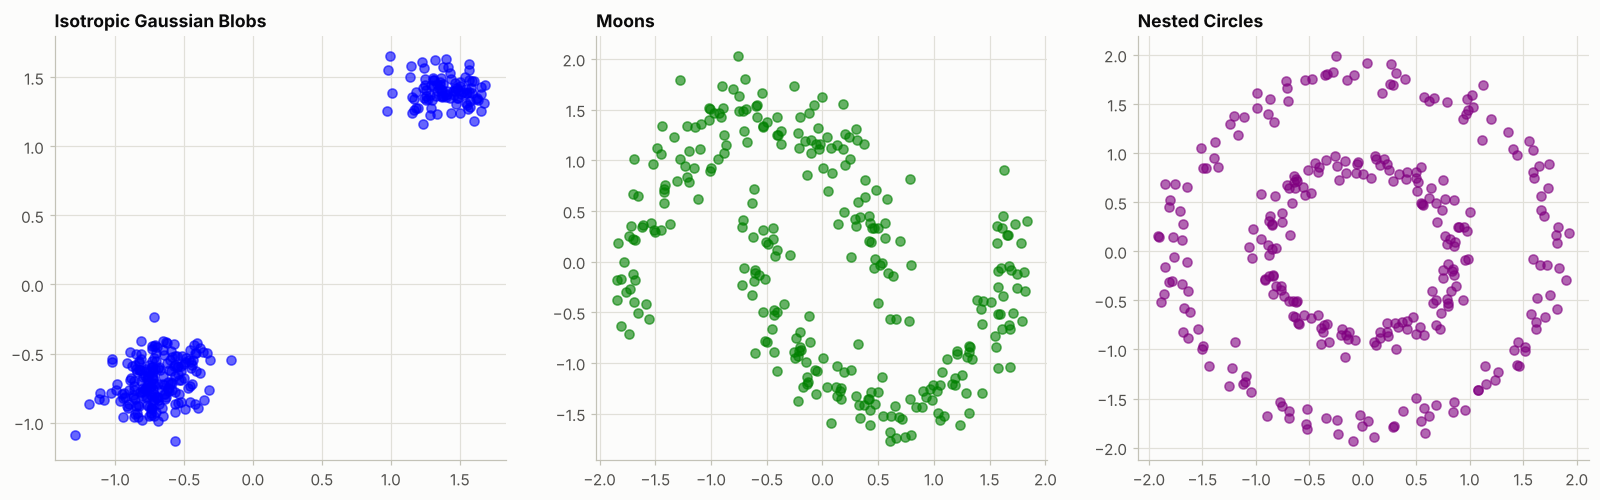

In [38]:
# BOOK CODE (pp. 271-272): visualize the datasets
# Visualize the datasets
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c='blue', alpha=0.6)
axs[0].set_title("Isotropic Gaussian Blobs")
axs[1].scatter(X_moons[:, 0], X_moons[:, 1], c='green', alpha=0.6)
axs[1].set_title("Moons")
axs[2].scatter(X_circles[:, 0], X_circles[:, 1], c='purple', alpha=0.6)
axs[2].set_title("Nested Circles")
plt.show()

**Output analysis.**

* The listing creates three standardized datasets and draws them (blue, green and purple, as in the book); **no clustering algorithm is applied**. The book's statement that "each data structure lends itself to a particular clustering algorithm" is therefore not tested by its code.
* The datasets are the isotropic blobs (3 centres), the moons and the nested circles. The book's comments (blobs for K-means or hierarchical clustering, moons for DBSCAN, circles "handled well by DBSCAN") are tested in extra (a).

### Extra: experiments for recipe 6

**(a) The algorithms the book only describes.** Six algorithms on the book's three datasets, with the true number of clusters where one is needed and the true labels (regenerated; the book discards them) to compute the ARI. The parameters are fixed in advance and are the same for every dataset: `DBSCAN(eps=0.3, min_samples=5)` (the value of the book's exercise 2), spectral clustering with the nearest-neighbour affinity (recipe 7), and a Gaussian mixture. Nothing is tuned per dataset.

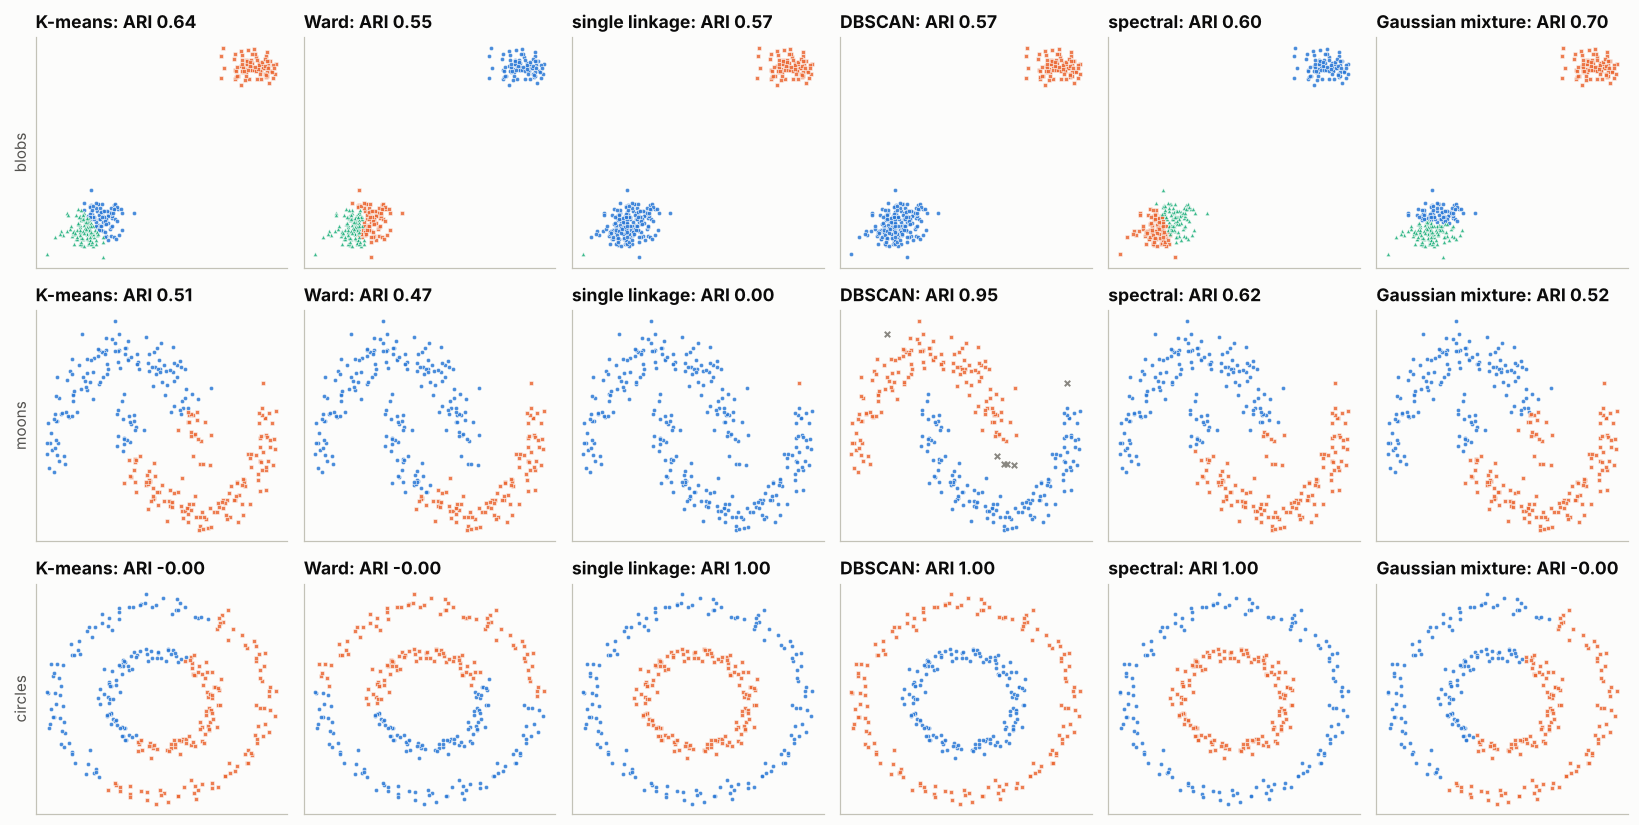

         K-means   Ward  single linkage  DBSCAN  spectral  Gaussian mixture
blobs      0.644  0.552           0.569   0.570     0.599             0.698
moons      0.507  0.470           0.000   0.948     0.618             0.517
circles   -0.003 -0.003           1.000   1.000     1.000            -0.003

best algorithm(s) per dataset: {'blobs': ['Gaussian mixture'], 'moons': ['DBSCAN'], 'circles': ['single linkage', 'DBSCAN', 'spectral']} 
DBSCAN labels 6 moon points as noise


In [39]:
# EXTRA: (a) six algorithms on blobs, moons and circles, scored with the true labels
from sklearn.cluster import SpectralClustering
from sklearn.mixture import GaussianMixture

truth = {"blobs": make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)[1],
         "moons": make_moons(n_samples=300, noise=0.1, random_state=2024)[1],
         "circles": make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)[1]}
datasets = {"blobs": (X_blobs, 3), "moons": (X_moons, 2), "circles": (X_circles, 2)}
algorithms = {
    "K-means": lambda k: KMeans(n_clusters=k, random_state=2024),
    "Ward": lambda k: AgglomerativeClustering(n_clusters=k),
    "single linkage": lambda k: AgglomerativeClustering(n_clusters=k, linkage="single"),
    "DBSCAN": lambda k: DBSCAN(eps=0.3, min_samples=5),
    "spectral": lambda k: SpectralClustering(n_clusters=k, affinity="nearest_neighbors", random_state=2024),
    "Gaussian mixture": lambda k: GaussianMixture(n_components=k, random_state=2024),
}
fig, axes = plt.subplots(3, 6, figsize=(15, 7.6))
rows = []
for r, (shape, (data, k)) in enumerate(datasets.items()):
    scores = {}
    for c, (name, make) in enumerate(algorithms.items()):
        labels_a = make(k).fit_predict(data)
        scores[name] = adjusted_rand_score(truth[shape], labels_a)
        scatter_clusters(axes[r, c], data, labels_a, title=f"{name}: ARI {scores[name]:.2f}", size=8)
        if shape == "moons" and name == "DBSCAN":
            noise_moons = int((labels_a == -1).sum())
    rows.append(pd.Series(scores, name=shape))
    axes[r, 0].set_ylabel(shape)
plt.tight_layout()
plt.show()
results = pd.DataFrame(rows)
print(results.round(3).to_string())
print("\nbest algorithm(s) per dataset:", {shape: [name for name in results.columns if results.loc[shape, name] >= results.loc[shape].max() - 1e-9] for shape in results.index},
      f"\nDBSCAN labels {noise_moons} moon points as noise")

**(b) Run time against the number of samples.** The book says K-means scales and hierarchical clustering does not. The cell times each algorithm (the best of three fits) on blobs of 1,000 to 8,000 points (4 clusters). Spectral clustering is run with the sparse nearest-neighbour affinity and, up to 4,000 points, with the default dense `rbf` affinity. The times depend on the machine; the growth is what matters.

                      1000  2000  4000  8000
K-means               0.00  0.00  0.00  0.01
MiniBatchKMeans       0.01  0.02  0.01  0.02
Ward                  0.01  0.07  0.28  1.56
DBSCAN                0.01  0.02  0.05  0.18
spectral, neighbours  0.15  0.18  0.20  0.30
spectral, rbf         0.31  0.40  2.75   NaN
Gaussian mixture      0.01  0.01  0.04  0.04


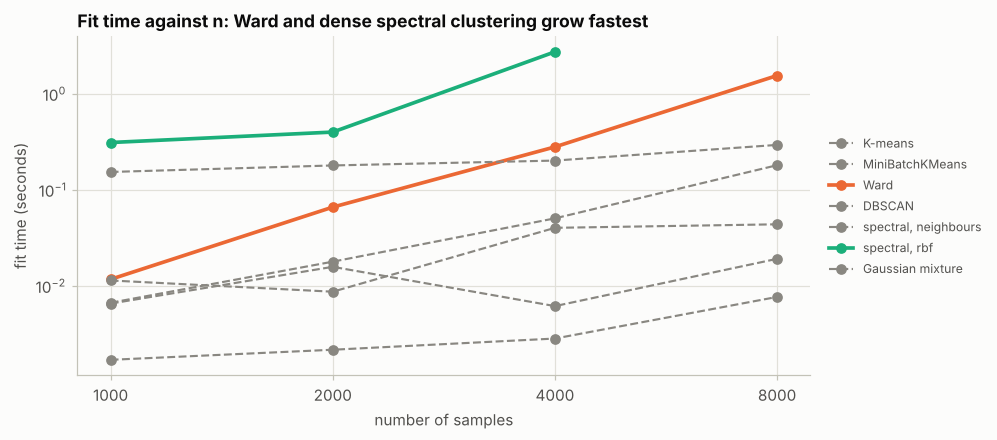

In [40]:
# EXTRA: (b) fit time against n (measured: the values depend on the machine)
import time

from sklearn.cluster import MiniBatchKMeans

timed = {
    "K-means": lambda: KMeans(n_clusters=4, random_state=0),
    "MiniBatchKMeans": lambda: MiniBatchKMeans(n_clusters=4, random_state=0),
    "Ward": lambda: AgglomerativeClustering(n_clusters=4),
    "DBSCAN": lambda: DBSCAN(eps=0.15, min_samples=5),
    "spectral, neighbours": lambda: SpectralClustering(n_clusters=4, affinity="nearest_neighbors", random_state=0),
    "spectral, rbf": lambda: SpectralClustering(n_clusters=4, random_state=0),
    "Gaussian mixture": lambda: GaussianMixture(n_components=4, random_state=0),
}
sizes = [1000, 2000, 4000, 8000]
seconds = {name: {} for name in timed}
for n in sizes:
    data = StandardScaler().fit_transform(make_blobs(n_samples=n, centers=4, cluster_std=0.6, random_state=2024)[0])
    for name, make in timed.items():
        if name == "spectral, rbf" and n > 4000:
            continue
        runs = []
        for _ in range(3):                                   # the best of three, to reduce the noise of the measurement
            start = time.perf_counter()
            make().fit(data)
            runs.append(time.perf_counter() - start)
        seconds[name][n] = min(runs)
timing = pd.DataFrame(seconds).T
print(timing.round(2).to_string())

fig, ax = plt.subplots(figsize=(8.6, 4))
styles = {"Ward": (PALETTE[1], "-"), "spectral, rbf": (PALETTE[2], "-")}
for name, row in timing.iterrows():
    color, style = styles.get(name, (MUTED, "--"))
    ax.plot(row.dropna().index, row.dropna().values, style, marker="o", color=color, label=name, linewidth=2.4 if name in styles else 1.4)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(sizes)
ax.set_xticklabels(sizes)
ax.minorticks_off()
ax.set_xlabel("number of samples")
ax.set_ylabel("fit time (seconds)")
ax.set_title("Fit time against n: Ward and dense spectral clustering grow fastest")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()

**(c) Irrelevant features, and PCA first.** The four blobs of recipe 1 (standardized) get $m$ extra features of pure noise with the same variance. The first table reports the ARI of K-means on all features, and of K-means after a PCA to two components, averaged over five draws of the noise. The next two outputs say what that PCA keeps: the variance along the two directions of the signal, and how much of the two kept components lies on the signal features. The last table shows the distance concentration that causes the damage: for points drawn at random in $d$ dimensions, the contrast between the farthest and the nearest neighbour of a point.

In [41]:
# EXTRA: (c) K-means with irrelevant features, with and without PCA; distance concentration
from sklearn.decomposition import PCA

signal = StandardScaler().fit_transform(make_blobs(n_samples=300, centers=4, cluster_std=0.6, random_state=2024)[0])
rows = []
for m in [0, 2, 5, 10, 20, 50, 100, 300]:
    plain, reduced = [], []
    for seed in range(5):
        noise = np.random.RandomState(seed).normal(size=(300, m))
        data = np.hstack([signal, noise])
        plain.append(adjusted_rand_score(y_true, KMeans(n_clusters=4, random_state=2024).fit_predict(data)))
        reduced.append(adjusted_rand_score(y_true, KMeans(n_clusters=4, random_state=2024).fit_predict(PCA(n_components=2).fit_transform(data))))
    rows.append({"noise features m": m, "K-means on all features": np.mean(plain), "K-means after PCA to 2 components": np.mean(reduced)})
print(pd.DataFrame(rows).set_index("noise features m").round(3).to_string())

print("\nvariance of the two directions of the standardized signal:", np.round(np.linalg.eigvalsh(np.cov(signal.T)), 2))
rows = []
for m in [2, 10, 50, 100, 300]:
    weight = [(PCA(n_components=2).fit(np.hstack([signal, np.random.RandomState(seed).normal(size=(300, m))])).components_[:, :2] ** 2).sum() for seed in range(5)]
    rows.append({"noise features m": m, "weight of the 2 kept components on the signal (maximum 2)": np.mean(weight)})
print(pd.DataFrame(rows).set_index("noise features m").round(2).to_string())

rows = []
for d in [2, 10, 100, 1000]:
    points = np.random.RandomState(0).normal(size=(300, d))
    distances = np.linalg.norm(points[1:] - points[0], axis=1)
    rows.append({"dimension d": d, "nearest": distances.min(), "farthest": distances.max(), "(farthest - nearest) / nearest": (distances.max() - distances.min()) / distances.min()})
print("\ndistances from one random point to 299 others:")
print(pd.DataFrame(rows).set_index("dimension d").round(2).to_string())

                  K-means on all features  K-means after PCA to 2 components
noise features m                                                            
0                                   0.801                              0.801
2                                   0.334                              0.337
5                                   0.384                              0.333
10                                  0.375                              0.334
20                                  0.350                              0.336
50                                  0.305                              0.314
100                                 0.058                              0.231
300                                 0.003                              0.069

variance of the two directions of the standardized signal: [0.04 1.96]
                  weight of the 2 kept components on the signal (maximum 2)
noise features m                                                           
2     

**Analysis of the extras.**

* **(a)** The best algorithm for the **moons** is DBSCAN (ARI 0.948, with 6 noise points), as the book says; the others reach 0.62 (spectral), 0.52, 0.51 and 0.47, and single linkage 0.00. For the **circles**, DBSCAN, spectral clustering and single linkage all score **1.00**, and K-means, Ward and the Gaussian mixture score 0. For the **blobs** the book recommends K-means or hierarchical clustering, but every algorithm scores between 0.55 and 0.70 and the Gaussian mixture is the best (0.698): this dataset also has two overlapping blobs, which no algorithm can separate cleanly. Spectral clustering reaches 0.62 on these moons (noise 0.1) against 1.00 on the cleaner moons of recipe 7: the noisier graph links the two crescents.
* **(b)** The times depend on the machine, but the growth does not. K-means, `MiniBatchKMeans` and the Gaussian mixture stay at a few hundredths of a second up to 8,000 points, and DBSCAN grows slowly. **Ward** grows faster than the number of samples: from 4,000 to 8,000 points its time is multiplied by about five, the price of the $n \times n$ distance matrix (the book's "less scalable"). **Spectral clustering** depends on the affinity: with the sparse neighbour graph it stays in the order of a fifth of a second, while with the default dense `rbf` affinity it grows quickly (about an order of magnitude slower at 4,000 points than the neighbour graph, and it needs $n^2$ memory). The book's "works well on large datasets" is true only for the sparse graph.
* **(c)** Irrelevant features are costly. With only 2 extra features of noise, the ARI of K-means drops from 0.801 to **0.334**; it stays between 0.30 and 0.38 up to 50 noise features and collapses to **0.058** at 100 and 0.003 (chance level) at 300. A PCA to two components first does **not** help for up to 50 noise features (0.31 to 0.34). After standardization the four blobs lie almost on a line: the variances of the two signal directions are 1.96 and 0.04, so the signal is essentially one direction, while each noise feature has a variance of 1. The two kept components therefore hold that one signal direction and a noise direction; their weight on the signal features is 1.00 (of a maximum of 2) with 2 noise features, 0.96 with 10 and 0.73 with 50. A PCA does help when the noise dominates (0.231 at 100 features, 0.069 at 300), although the kept components then carry only 0.52 and 0.13 of signal; the gain most likely comes from going down to 2 dimensions, which removes the distance concentration shown next, and not from a better view of the signal. The distances show why the damage is so large: for random points, the relative contrast between the farthest and the nearest neighbour falls from 22 at $d = 2$ to 2.0 at $d = 10$, 0.36 at $d = 100$ and 0.11 at $d = 1000$. The book's advice to reduce the dimension first is sound, but only if the reduction keeps the structure.

---
## 7. Advanced clustering techniques

### Summary

* "Beyond the classic clustering algorithms, scikit-learn offers several advanced techniques such as spectral clustering and Gaussian Mixture Models (GMMs)", which "provide more flexibility in modeling complex cluster shapes and probabilistic cluster assignments".
* **Getting ready** — import `SpectralClustering` and `GaussianMixture`, and create two standardized moons with `noise=0.05`.
* **How to do it** — `SpectralClustering(n_clusters=2, affinity='nearest_neighbors', random_state=2024)` and `GaussianMixture(n_components=2, random_state=2024)`, each with `fit_predict`, and two scatter plots (Figure 10.9). The book's reading: "Spectral clustering handles the curved shape better, while GMM models the underlying probability distributions."
* **How it works** — **spectral clustering** builds a similarity graph, builds a matrix of the relationships between the points, maps the graph to a lower-dimensional space, and applies K-means there; it "is effective for non-convex clusters" and "also works well on large datasets with many features". **GMMs** are a "soft clustering method" assuming the data comes from a mixture of Gaussians; each point gets a probability for each cluster, and the **Expectation-Maximization (EM)** algorithm finds the parameters that maximize the likelihood. GMMs capture "elliptical shapes and overlapping clusters" and can serve for anomaly detection.
* **There's more** — `predict_proba` gives the probability of each cluster for each point; these probabilities "can sometimes be over- or under-confident" (the book points to `CalibratedClassifierCV`). Spectral clustering can benefit from dimensionality reduction (PCA, t-SNE) before it.
* **Hands-on exercises** — six steps: spectral clustering and a GMM on moons or circles, `predict` and `predict_proba`, overlapping and curved clusters, varying the number of components, dimensionality reduction first.

### Theory: clustering a graph, and clustering with probabilities

**Spectral clustering** (Shi and Malik, 2000; Ng, Jordan and Weiss, 2001; von Luxburg, 2007) treats the samples as the nodes of a graph and cuts the graph into well-connected parts.

1. **Affinity matrix** $W$, with $W_{ij}$ large for similar points: either the symmetrized **nearest-neighbour graph** ($W_{ij} = 1$ if $j$ is among the $k$ nearest neighbours of $i$ or the reverse), or the **RBF kernel** $W_{ij} = \exp(-\gamma \lVert \mathbf{x}_i - \mathbf{x}_j \rVert^2)$.
2. **Normalized Laplacian** $L = I - D^{-1/2} W D^{-1/2}$, where $D$ is the diagonal matrix of the row sums of $W$.
3. **Spectral embedding**: the eigenvectors of $L$ for its $K$ smallest eigenvalues; row $i$ is the new, $K$-dimensional coordinate of sample $i$.
4. **K-means** on the rows of the embedding.

*Why it works.* Cutting a graph into pieces with few edges between them, balanced by their size (the **normalized cut**), is NP-hard; relaxing it gives exactly the eigenvectors of $L$. The eigenvalue 0 has a multiplicity equal to the number of **connected components** of the graph, and the eigenvectors of those zero eigenvalues are constant on each component. In the embedding, the components (or, for a graph that is almost disconnected, the almost-components) become tight groups of points that K-means separates easily, whatever their shape in the original space. A large gap after the $K$-th smallest eigenvalue (the **eigengap**) suggests $K$.

*Cost.* The embedding needs an eigen-decomposition. With a **sparse** neighbour graph it is cheap (an iterative solver on a sparse matrix); with the default **dense `rbf` affinity** the matrix has $n^2$ entries, which limits $n$ to a few thousand (recipe 6 measures it). The result depends on the graph: too few neighbours break it into many components, too many connect clusters that should be apart.

**Gaussian mixture model** (Dempster, Laird and Rubin, 1977, for EM). The density is a weighted sum of $K$ Gaussians,

$$
p(\mathbf{x}) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \Sigma_k), \qquad \pi_k \ge 0, \;\; \sum_k \pi_k = 1 .
$$

The **responsibility** of component $k$ for sample $i$ is the posterior probability $\gamma_{ik} = \dfrac{\pi_k \, \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_k, \Sigma_k)}{\sum_j \pi_j \, \mathcal{N}(\mathbf{x}_i \mid \boldsymbol{\mu}_j, \Sigma_j)}$. **EM** alternates:

* **E-step**: compute all $\gamma_{ik}$ with the current parameters.
* **M-step**: with $N_k = \sum_i \gamma_{ik}$,
  $\pi_k = N_k / n$, $\quad \boldsymbol{\mu}_k = \frac{1}{N_k} \sum_i \gamma_{ik} \mathbf{x}_i$, $\quad \Sigma_k = \frac{1}{N_k} \sum_i \gamma_{ik} (\mathbf{x}_i - \boldsymbol{\mu}_k)(\mathbf{x}_i - \boldsymbol{\mu}_k)^\top$.

The log-likelihood never decreases, so EM converges to a local maximum; scikit-learn starts it from a K-means partition (`init_params='kmeans'`). `predict_proba` returns the $\gamma_{ik}$, and `predict` returns $\arg\max_k \gamma_{ik}$. K-means is the special case with equal spherical covariances and hard assignments.

**Covariance types** control the shape of the components and the number of parameters: `full` (each component its own ellipse), `tied` (one ellipse shared), `diag` (axis-aligned ellipses) and `spherical` (circles). The **BIC**, $\text{BIC} = p \ln n - 2 \ln \hat{L}$ with $p$ the number of parameters (lower is better), chooses $K$ and the covariance type: it rewards the fit and penalizes the parameters.

**Probabilities are model-based.** A GMM's posterior is correct only if the data really is a mixture of Gaussians. A moon is not a Gaussian, so the probabilities for moons can be **confidently wrong**. Calibration (`CalibratedClassifierCV`, Chapter 7) is defined for classifiers that have labelled training data; it does not apply directly to an unsupervised mixture.

### Book code (pp. 274–277)

In [42]:
# BOOK CODE (p. 274): load the libraries and create the two moons (noise 0.05, standardized)
# Load the libraries
from sklearn.cluster import SpectralClustering
from sklearn.mixture import GaussianMixture
# Create datasets with complex structure
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

X, _ = make_moons(n_samples=300, noise=0.05, random_state=2024)
X = StandardScaler().fit_transform(X)

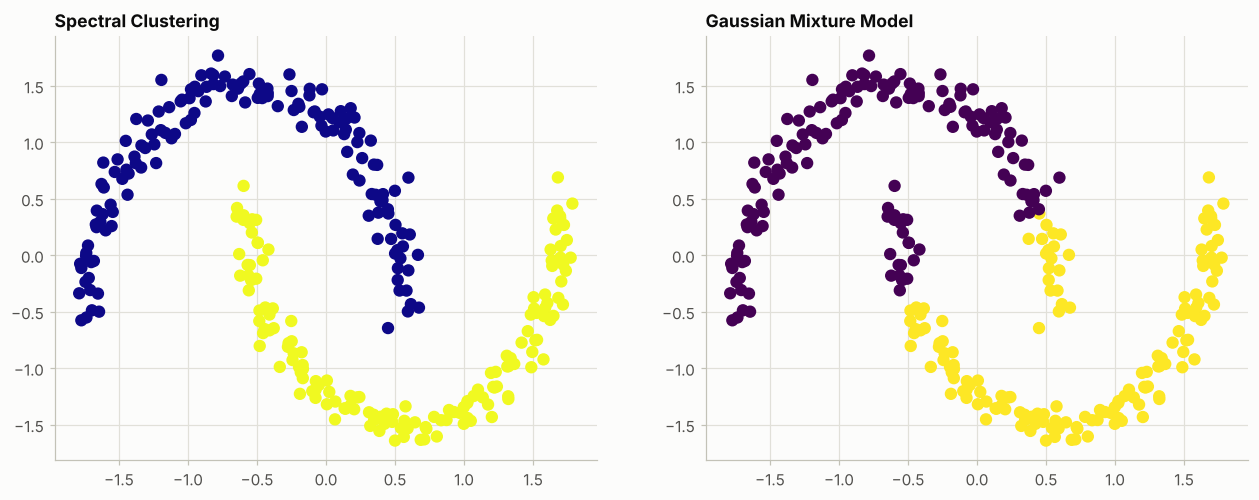

In [43]:
# BOOK CODE (pp. 274-275): spectral clustering and a Gaussian mixture, side by side
# Apply Spectral Clustering
spectral = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', random_state=2024)
y_spectral = spectral.fit_predict(X)

# Apply Gaussian Mixture Model
gmm = GaussianMixture(n_components=2, random_state=2024)
y_gmm = gmm.fit_predict(X)

# Visualize both clustering results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(X[:, 0], X[:, 1], c=y_spectral, cmap='plasma', s=50)
ax1.set_title("Spectral Clustering")

ax2.scatter(X[:, 0], X[:, 1], c=y_gmm, cmap='viridis', s=50)
ax2.set_title("Gaussian Mixture Model")

plt.show()

In [44]:
# EXTRA: inspect what the book's code produced (the true moon of each point is what the book discards)
y_moons = make_moons(n_samples=300, noise=0.05, random_state=2024)[1]
print(f"spectral clustering: ARI with the true moons {adjusted_rand_score(y_moons, y_spectral):.3f}; cluster sizes {np.bincount(y_spectral).tolist()}")
print(f"Gaussian mixture   : ARI with the true moons {adjusted_rand_score(y_moons, y_gmm):.3f}; cluster sizes {np.bincount(y_gmm).tolist()}; converged: {gmm.converged_} after {gmm.n_iter_} iterations")
print(f"GMM weights {np.round(gmm.weights_, 3).tolist()}, covariance_type={gmm.covariance_type!r}")
print(f"average of the largest probability per point: {gmm.predict_proba(X).max(axis=1).mean():.3f}")

spectral clustering: ARI with the true moons 1.000; cluster sizes [150, 150]
Gaussian mixture   : ARI with the true moons 0.526; cluster sizes [151, 149]; converged: True after 3 iterations
GMM weights [0.501, 0.499], covariance_type='full'
average of the largest probability per point: 0.964


**Output analysis.**

* **Spectral clustering recovers the two moons exactly** (ARI 1.000, clusters of 150 and 150). The **Gaussian mixture does not** (ARI 0.526, clusters of 151 and 149): it cuts across both moons with two elliptical components, a poor description of a crescent. It converges after 3 iterations.
* The book's sentence "spectral clustering handles the curved shape better, while GMM models the underlying probability distributions" is correct, with one precision: the mixture's two Gaussians are not the two moons, so its clusters are not the clusters one wants here.
* The average of the largest probability per point is **0.964**: the mixture is confident although its clusters are wrong; extra (f) measures how far that confidence can be trusted.

### Extra: experiments for recipe 7

**(a) Spectral clustering by hand.** The four steps of the theory in NumPy: the symmetrized 10-nearest-neighbour graph (`SpectralClustering`'s default `n_neighbors`), the normalized Laplacian, its smallest eigenvalues, and K-means on the two eigenvectors. The result is compared with the library's. The figure shows the data and the spectral embedding.

connected components of the neighbour graph: 2
smallest eigenvalues of the Laplacian: [0.0, 0.0, 0.0022, 0.0026, 0.0076, 0.0092]
by hand vs scikit-learn: ARI 1.000; by hand vs the true moons: ARI 1.000


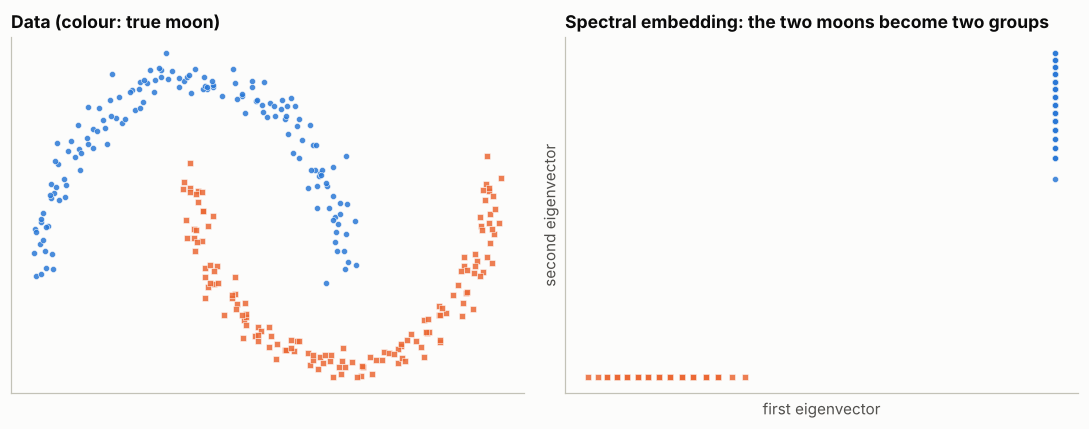

In [45]:
# EXTRA: (a) spectral clustering in NumPy
from scipy.sparse.csgraph import connected_components, laplacian
from sklearn.cluster import KMeans
from sklearn.neighbors import kneighbors_graph

graph = kneighbors_graph(X, n_neighbors=10, include_self=True)
affinity = 0.5 * (graph + graph.T)                                   # symmetrized neighbour graph
n_components, _ = connected_components(affinity)
L = laplacian(affinity.toarray(), normed=True)                       # I - D^(-1/2) W D^(-1/2)
eigenvalues, eigenvectors = np.linalg.eigh(L)
embedding = eigenvectors[:, :2]                                      # the eigenvectors of the 2 smallest eigenvalues
labels_by_hand = KMeans(n_clusters=2, n_init=10, random_state=2024).fit_predict(embedding)

print(f"connected components of the neighbour graph: {n_components}")
print("smallest eigenvalues of the Laplacian:", np.round(eigenvalues[:6], 4).tolist())
print(f"by hand vs scikit-learn: ARI {adjusted_rand_score(labels_by_hand, y_spectral):.3f}; by hand vs the true moons: ARI {adjusted_rand_score(y_moons, labels_by_hand):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
scatter_clusters(axes[0], X, y_moons, title="Data (colour: true moon)", size=16)
scatter_clusters(axes[1], embedding, y_moons, title="Spectral embedding: the two moons become two groups", size=16)
axes[1].set_xlabel("first eigenvector")
axes[1].set_ylabel("second eigenvector")
axes[1].set_xticks([])
axes[1].set_yticks([])
plt.tight_layout()
plt.show()

**(b) The affinity graph decides.** Spectral clustering of the same moons for several numbers of neighbours, and for the RBF affinity with several values of `gamma` (the default is 1). For the neighbour graph the number of connected components is also given: if it exceeds the number of clusters, the graph has fallen apart. The cell counts the warnings that scikit-learn raises in that case.

In [46]:
# EXTRA: (b) n_neighbors and gamma
rows = []
for n_neighbors in (3, 5, 10, 20, 50):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        labels_b = SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=n_neighbors, random_state=2024).fit_predict(X)
    graph_b = kneighbors_graph(X, n_neighbors=n_neighbors, include_self=True)
    rows.append({"affinity": f"nearest neighbours, k={n_neighbors}", "connected components": connected_components(0.5 * (graph_b + graph_b.T))[0],
                 "warning: graph not fully connected": any("not fully connected" in str(w.message) for w in caught),
                 "ARI with the true moons": adjusted_rand_score(y_moons, labels_b)})
for gamma in (1, 5, 20, 50):
    labels_b = SpectralClustering(n_clusters=2, affinity="rbf", gamma=gamma, random_state=2024).fit_predict(X)
    rows.append({"affinity": f"rbf, gamma={gamma}", "connected components": "complete graph", "warning: graph not fully connected": False,
                 "ARI with the true moons": adjusted_rand_score(y_moons, labels_b)})
print(pd.DataFrame(rows).set_index("affinity").round(3).to_string())

                         connected components  warning: graph not fully connected  ARI with the true moons
affinity                                                                                                  
nearest neighbours, k=3                    19                                True                    0.006
nearest neighbours, k=5                     5                                True                    0.005
nearest neighbours, k=10                    2                                True                    1.000
nearest neighbours, k=20                    1                               False                    1.000
nearest neighbours, k=50                    1                               False                    0.586
rbf, gamma=1                   complete graph                               False                    0.546
rbf, gamma=5                   complete graph                               False                    0.973
rbf, gamma=20                  comple

**(c) EM by hand.** The two steps of the theory for a mixture of four Gaussians with full covariances on the standardized blobs of recipe 1, started like scikit-learn (from the partition of a K-means with one start) and stopped when the mean log-likelihood changes by less than `tol=1e-3`. It reproduces the library's parameters, and the log-likelihood increases at every iteration.

In [47]:
# EXTRA: (c) the EM algorithm in NumPy, compared with GaussianMixture
from scipy.stats import multivariate_normal

blobs = StandardScaler().fit_transform(make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)[0])
K, n = 4, len(blobs)
responsibilities = np.eye(K)[KMeans(n_clusters=K, n_init=1, random_state=2024).fit(blobs).labels_]   # the start of scikit-learn (init_params='kmeans')


def m_step(resp):
    """New weights, means and covariances from the responsibilities (the same regularization as scikit-learn: 1e-6 on the diagonal)."""
    N = resp.sum(axis=0) + 10 * np.finfo(resp.dtype).eps
    means = resp.T @ blobs / N[:, None]
    covs = np.array([(resp[:, k, None] * (blobs - means[k])).T @ (blobs - means[k]) / N[k] + 1e-6 * np.eye(2) for k in range(K)])
    return N / n, means, covs


weights, means, covs = m_step(responsibilities)
previous, log_likelihood = -np.inf, []
for iteration in range(100):
    density = np.column_stack([weights[k] * multivariate_normal(means[k], covs[k]).pdf(blobs) for k in range(K)])
    log_likelihood.append(np.log(density.sum(axis=1)).mean())                                           # E-step: the mean log-likelihood ...
    responsibilities = density / density.sum(axis=1, keepdims=True)                                     # ... and the responsibilities
    weights, means, covs = m_step(responsibilities)                                                      # M-step
    if abs(log_likelihood[-1] - previous) < 1e-3:
        break
    previous = log_likelihood[-1]

reference = GaussianMixture(n_components=K, random_state=2024, tol=1e-3).fit(blobs)
order = [int(np.argmin(((reference.means_ - m) ** 2).sum(axis=1))) for m in means]
print(f"by hand: {len(log_likelihood)} iterations; scikit-learn: {reference.n_iter_} iterations")
print("mean log-likelihood per iteration:", [round(float(v), 4) for v in log_likelihood])
print(f"log-likelihood never decreases: {bool(np.all(np.diff(log_likelihood) >= -1e-12))}")
print(f"same means: {np.allclose(means, reference.means_[order], atol=1e-6)}; same weights: {np.allclose(weights, reference.weights_[order], atol=1e-6)}; "
      f"same covariances: {np.allclose(covs, reference.covariances_[order], atol=1e-6)}; mean log-likelihood by hand {log_likelihood[-1]:.5f}, scikit-learn (before the last M-step) {reference.lower_bound_:.5f}")

by hand: 5 iterations; scikit-learn: 5 iterations
mean log-likelihood per iteration: [0.2941, 0.3031, 0.3056, 0.3068, 0.3075]
log-likelihood never decreases: True
same means: True; same weights: True; same covariances: True; mean log-likelihood by hand 0.30748, scikit-learn (before the last M-step) 0.30748


**(d) Choosing the number of components and the covariance type with the BIC.** For the same blobs, the BIC of mixtures with 1 to 7 components and the four covariance types. The generator draws all four blobs with the same spread, which is the assumption of the `tied` type.

             full   tied    diag  spherical
components                                 
1           985.9  985.9  1725.5     1719.8
2           -23.7  103.9   -10.8      142.7
3           -79.1  -77.3   -85.8      -88.5
4           -53.6  -95.1   -71.1      -79.0
5           -26.6  -78.7   -48.7      -74.4
6            -2.6  -62.1   -30.6      -63.6
7            28.1  -52.2    -6.3      -46.7

best number of components by BIC: {'full': 3, 'tied': 4, 'diag': 3, 'spherical': 3}
lowest BIC overall: -95.1 (tied covariance, 4 components)


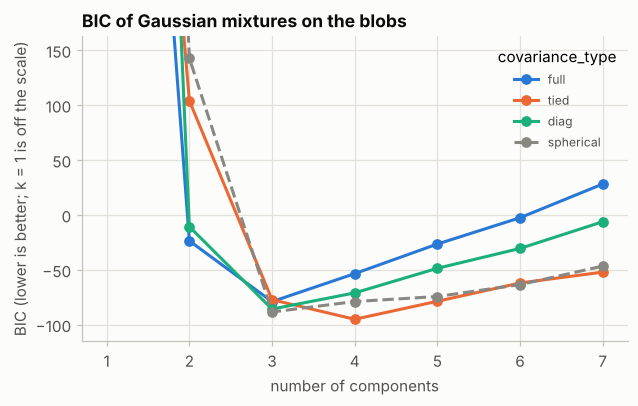

In [48]:
# EXTRA: (d) BIC for K = 1..7 and the four covariance types
bic = pd.DataFrame({covariance: [GaussianMixture(n_components=k, covariance_type=covariance, random_state=2024).fit(blobs).bic(blobs) for k in range(1, 8)]
                    for covariance in ("full", "tied", "diag", "spherical")}, index=range(1, 8))
bic.index.name = "components"
print(bic.round(1).to_string())
print("\nbest number of components by BIC:", {covariance: int(bic[covariance].idxmin()) for covariance in bic.columns})
print(f"lowest BIC overall: {bic.min().min():.1f} ({bic.min().idxmin()} covariance, {int(bic[bic.min().idxmin()].idxmin())} components)")

fig, ax = plt.subplots(figsize=(6.4, 3.6))
for covariance, color, style in zip(bic.columns, [PALETTE[0], PALETTE[1], PALETTE[2], MUTED], ["-", "-", "-", "--"]):
    ax.plot(bic.index, bic[covariance], style, marker="o", color=color, label=covariance)
ax.set_ylim(bic.drop(index=1).min().min() - 20, bic.drop(index=1).max().max() + 20)
ax.set_xlabel("number of components")
ax.set_ylabel("BIC (lower is better; k = 1 is off the scale)")
ax.set_title("BIC of Gaussian mixtures on the blobs")
ax.legend(title="covariance_type", fontsize=8)
plt.show()

**(e) Soft assignments: where the mixture is unsure.** The mixture of recipe 1's blobs gives each point a probability for each component. The points whose largest probability is below 0.9 are the ones the book's `predict_proba` remark is about. The cell shows where they are, and how many of them belong to the two overlapping true blobs.

points with a largest probability below 0.9: 60 of 300
true blob of those points: {1: 23, 2: 34, 3: 3} (blobs 1 and 2 are the close pair)


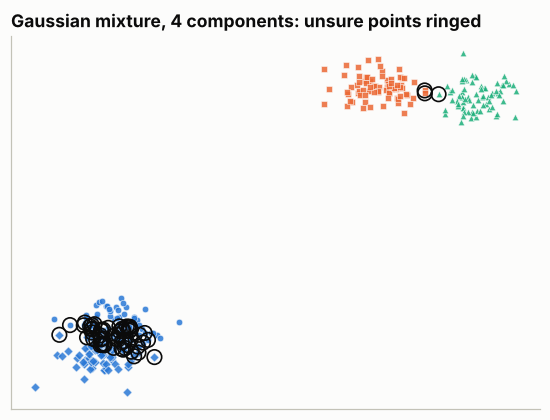

In [49]:
# EXTRA: (e) points with an uncertain assignment
mixture = GaussianMixture(n_components=4, random_state=2024).fit(blobs)
proba = mixture.predict_proba(blobs)
confidence = proba.max(axis=1)
uncertain = confidence < 0.9
print(f"points with a largest probability below 0.9: {uncertain.sum()} of {len(blobs)}")
print("true blob of those points:", dict(zip(*[v.tolist() for v in np.unique(y_true[uncertain], return_counts=True)])), "(blobs 1 and 2 are the close pair)")

fig, ax = plt.subplots(figsize=(6.2, 4.4))
scatter_clusters(ax, blobs, mixture.predict(blobs), title="Gaussian mixture, 4 components: unsure points ringed", size=18)
ax.scatter(*blobs[uncertain].T, facecolors="none", edgecolors=INK, s=90, linewidths=1.1)
plt.show()

**(f) Confidently wrong.** The book's mixture of two components on the moons gets the shape wrong. How sure does it claim to be? The cell groups the points by their largest probability and reports, for each group, the share of points that sit in the right moon (the better of the two possible matchings of components to moons). It then shows how the BIC behaves when the mixture is given more components than clusters.

In [50]:
# EXTRA: (f) the confidence of the book's moon mixture against its correctness, and the BIC for more components
proba_moons = gmm.predict_proba(X)
hard = proba_moons.argmax(axis=1)
right = (hard == y_moons) if (hard == y_moons).mean() >= 0.5 else (hard != y_moons)       # the better matching of components to moons
confidence_m = proba_moons.max(axis=1)
rows = []
for name, low, high in [("0.99 or more", 0.99, 1.01), ("0.90 to 0.99", 0.90, 0.99), ("below 0.90", 0.0, 0.90)]:
    group = (confidence_m >= low) & (confidence_m < high)
    rows.append({"largest probability": name, "points": int(group.sum()), "share in the right moon": right[group].mean()})
print(pd.DataFrame(rows).set_index("largest probability").round(3).to_string())
print(f"\nmean claimed confidence {confidence_m.mean():.3f}, actual share of correct points {right.mean():.3f}")

bic_moons = [GaussianMixture(n_components=k, random_state=2024).fit(X).bic(X) for k in range(1, 11)]
print("BIC of the moons for 1 to 10 components:", [int(round(v)) for v in bic_moons], f"-> lowest at {int(np.argmin(bic_moons)) + 1} components")

                     points  share in the right moon
largest probability                                 
0.99 or more            225                    0.969
0.90 to 0.99             35                    0.543
below 0.90               40                    0.550

mean claimed confidence 0.964, actual share of correct points 0.863
BIC of the moons for 1 to 10 components: [1666, 1597, 1517, 1319, 1276, 1195, 1086, 1074, 1049, 1067] -> lowest at 9 components


**Analysis of the extras.**

* **(a)** The symmetrized 10-nearest-neighbour graph has **2 connected components** (the two moons), and the Laplacian has exactly **two eigenvalues equal to 0**, one per component (then 0.0022, 0.0026, ...). K-means on the two eigenvectors reproduces the library's labelling (ARI 1.000) and the truth. In the embedding, each moon collapses onto a segment along one axis (the segments are scaled by the degrees of the nodes), so that K-means separates them trivially.
* **(b)** The graph decides. With 3 neighbours the graph breaks into **19 components** and with 5 into 5: spectral clustering then fails (ARI 0.006 and 0.005, with a warning). With 10 neighbours there are 2 components and the ARI is 1.000 (the warning only says that the graph is not connected, which here is the structure); with 20 the graph is connected and still works; with **50 neighbours** it links the two moons across the gap and the ARI drops to 0.586. For the `rbf` affinity, the default `gamma=1` is too smooth (ARI 0.546); 5 gives 0.973, and 20 and 50 give 1.000.
* **(c)** The by-hand EM converges in 5 iterations, like the library, and its mean log-likelihood rises at every iteration (0.2941, 0.3031, 0.3056, 0.3068, 0.3075). The weights, means and covariances equal scikit-learn's to $10^{-6}$, and the final mean log-likelihood equals `lower_bound_`.
* **(d)** The BIC picks 3 components for the `full`, `diag` and `spherical` types (the two overlapping blobs are merged: the extra parameters of a fourth component cost more than the fit gains) and **4 components for `tied`**, which has the lowest BIC overall (-95.1). The tied model is the one that generated the data: four blobs with the same spread. The best model depends on the covariance type allowed, not only on the data.
* **(e)** **60 of the 300 points** have a largest probability below 0.9, and **57 of them belong to the two overlapping true blobs** (23 and 34); the other 3 are from blob 3. Hard labels, as in K-means, give no hint that these points are uncertain.
* **(f)** The two-component mixture on the moons claims a mean confidence of 0.964 and is right for 86.3% of the points. The 225 points with a probability of at least 0.99 are in the right moon 96.9% of the time, but the 35 points between 0.90 and 0.99 only 54.3% of the time, and the 40 below 0.90, 55.0%: the probabilities are partly informative and **overconfident**, because they are computed under a wrong model. The BIC keeps falling up to 9 components (1049): a mixture can describe the density of the moons with many Gaussians, but then its components are no longer the clusters.

---
## 8. Practical exercises with clustering models

### Summary

The book ends with three exercises (the printed edition gives only the steps, the official notebook gives the code):

1. **Clustering with K-means on the Iris dataset** — fit `KMeans(n_clusters=3)`, evaluate with the silhouette score and the ARI, and draw the clusters in a PCA projection.
2. **Comparing DBSCAN and K-means on moons data** — "DBSCAN can outperform K-means on data with non-convex shapes".
3. **Clustering high-dimensional data with PCA and GMMs** — reduce the standardized Wine data to two components and fit a three-component mixture.

The cells below are the official solutions. The extras add the numbers that the exercises do not print.

### Exercise 1: Clustering with K-means on the Iris dataset (official solution)

Silhouette Score: 0.553
Adjusted Rand Index: 0.730


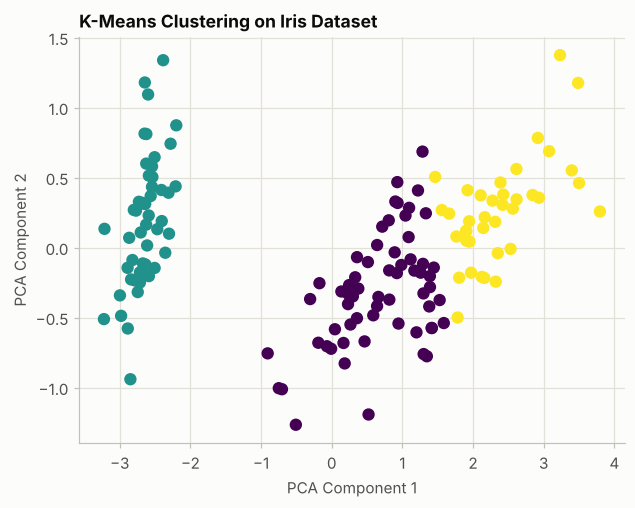

In [51]:
# BOOK CODE (official solution, exercise 1)
# Load libraries
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import matplotlib.pyplot as plt

# Load the Dataset
iris = load_iris()
X = iris.data
y_true = iris.target

# Create and Train the KMeans Model
kmeans = KMeans(n_clusters=3, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

# Evaluate the Clustering
sil_score = silhouette_score(X, y_kmeans)
ari = adjusted_rand_score(y_true, y_kmeans)

print(f"Silhouette Score: {sil_score:.3f}")
print(f"Adjusted Rand Index: {ari:.3f}")

# Visualize the Cluster Assignments (PCA Projection)
from sklearn.decomposition import PCA

X_pca = PCA(n_components=2).fit_transform(X)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_kmeans, cmap='viridis', s=50)
plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

In [52]:
# EXTRA: exercise 1 -- clusters against species, the number of clusters, and the effect of standardizing
print("clusters (columns) against species (rows):")
print(pd.crosstab(pd.Series(iris.target_names[y_true], name="species"), pd.Series(y_kmeans, name="cluster")).to_string())
print(f"samples outside the majority cluster of their species: {len(y_true) - sum(pd.crosstab(y_true, y_kmeans).max(axis=1))} of {len(y_true)}")
print(f"variance of the data kept by the two PCA components of the figure: {PCA(n_components=2).fit(X).explained_variance_ratio_.sum():.1%}")

rows = []
for k in range(2, 9):
    labels_k = KMeans(n_clusters=k, random_state=2024).fit_predict(X)
    rows.append({"k": k, "silhouette": silhouette_score(X, labels_k), "ARI with the species": adjusted_rand_score(y_true, labels_k)})
print("\nthe number of clusters:")
print(pd.DataFrame(rows).set_index("k").round(3).to_string())

scaled_labels = KMeans(n_clusters=3, random_state=2024).fit_predict(StandardScaler().fit_transform(X))
print(f"\nk=3 after StandardScaler: silhouette {silhouette_score(StandardScaler().fit_transform(X), scaled_labels):.3f}, ARI {adjusted_rand_score(y_true, scaled_labels):.3f} (raw: {ari:.3f})")

clusters (columns) against species (rows):
cluster      0   1   2
species               
setosa       0  50   0
versicolor  48   0   2
virginica   14   0  36
samples outside the majority cluster of their species: 16 of 150
variance of the data kept by the two PCA components of the figure: 97.8%

the number of clusters:
   silhouette  ARI with the species
k                                  
2       0.681                 0.540
3       0.553                 0.730
4       0.495                 0.610
5       0.360                 0.455
6       0.359                 0.455
7       0.345                 0.481
8       0.342                 0.459

k=3 after StandardScaler: silhouette 0.460, ARI 0.620 (raw: 0.730)


### Exercise 2: Comparing DBSCAN and K-means on moons data (official solution)

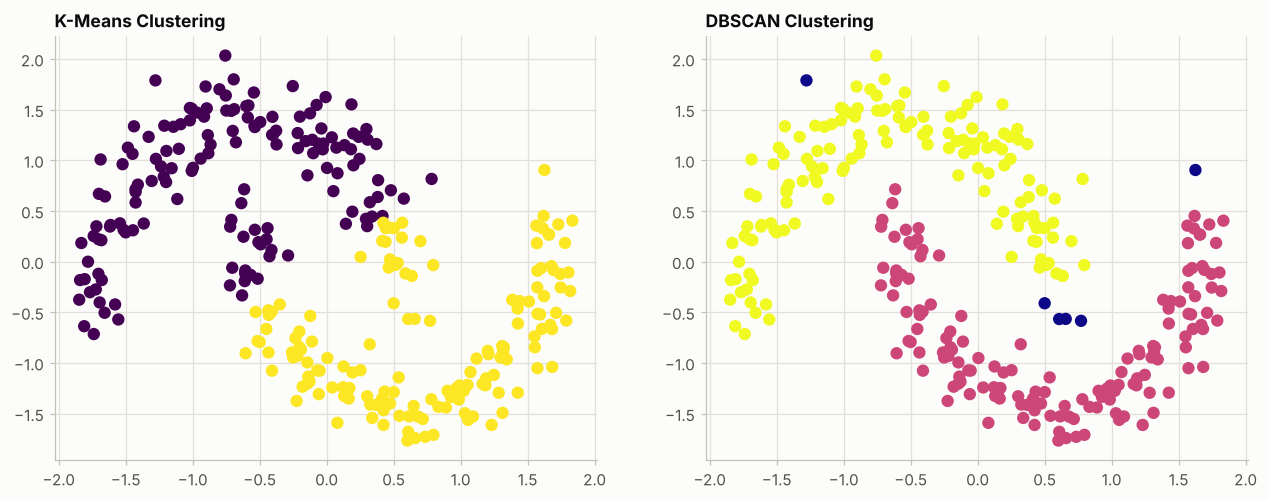

In [53]:
# BOOK CODE (official solution, exercise 2)
# Load libraries
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
import matplotlib.pyplot as plt

# Create and Scale the Dataset
X, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)
X = StandardScaler().fit_transform(X)

# Apply KMeans and DBSCAN
kmeans = KMeans(n_clusters=2, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

dbscan = DBSCAN(eps=0.3, min_samples=5)
y_dbscan = dbscan.fit_predict(X)

# Visualize the Clustering Results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(X[:, 0], X[:, 1], c=y_kmeans, cmap='viridis', s=50)
ax1.set_title("K-Means Clustering")

ax2.scatter(X[:, 0], X[:, 1], c=y_dbscan, cmap='plasma', s=50)
ax2.set_title("DBSCAN Clustering")

plt.show()

In [54]:
# EXTRA: exercise 2 -- scores, the noise points, and how the result depends on eps
y_moons2 = make_moons(n_samples=300, noise=0.1, random_state=2024)[1]
not_noise = y_dbscan != -1
print(f"K-means: ARI {adjusted_rand_score(y_moons2, y_kmeans):.3f}")
print(f"DBSCAN : ARI {adjusted_rand_score(y_moons2, y_dbscan):.3f} (the {int((~not_noise).sum())} noise points count as one extra cluster); "
      f"ARI on the {int(not_noise.sum())} clustered points: {adjusted_rand_score(y_moons2[not_noise], y_dbscan[not_noise]):.3f}")

rows = []
for eps in (0.1, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5):
    labels_e = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
    rows.append({"eps": eps, "clusters": len(set(labels_e)) - (1 if -1 in labels_e else 0), "noise points": int((labels_e == -1).sum()),
                 "ARI with the true moons": adjusted_rand_score(y_moons2, labels_e)})
print("\nDBSCAN, min_samples=5, on the standardized moons:")
print(pd.DataFrame(rows).set_index("eps").round(3).to_string())

K-means: ARI 0.507
DBSCAN : ARI 0.948 (the 6 noise points count as one extra cluster); ARI on the 294 clustered points: 0.986

DBSCAN, min_samples=5, on the standardized moons:
      clusters  noise points  ARI with the true moons
eps                                                  
0.10        10           236                    0.010
0.20         8            26                    0.380
0.25         2            12                    0.923
0.30         2             6                    0.948
0.35         2             2                    0.973
0.40         1             1                    0.000
0.50         1             0                    0.000


### Exercise 3: Clustering high-dimensional data with PCA and GMMs (official solution)

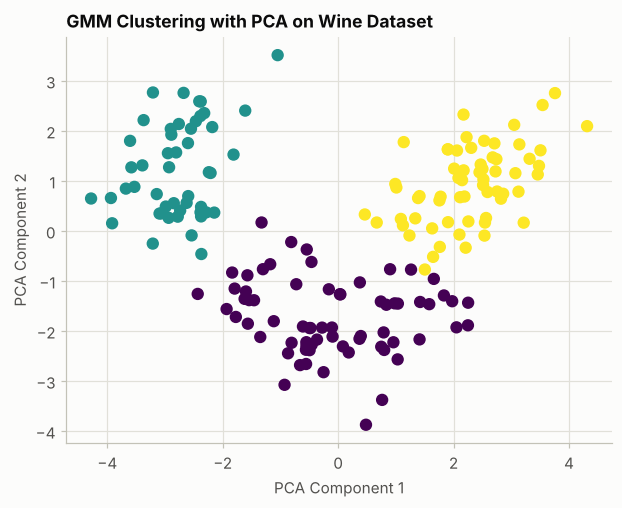

In [55]:
# BOOK CODE (official solution, exercise 3)
# Load libraries
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

# Load and Preprocess the Dataset
data = load_wine()
X = StandardScaler().fit_transform(data.data)

# Apply PCA for Dimensionality Reduction
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Fit Gaussian Mixture Model
gmm = GaussianMixture(n_components=3, random_state=2024)
y_gmm = gmm.fit_predict(X_pca)

# Visualize the Clustered Output
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_gmm, cmap='viridis', s=50)
plt.title("GMM Clustering with PCA on Wine Dataset")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

In [56]:
# EXTRA: exercise 3 -- the clusters against the three wine cultivars, and what PCA costs
cultivars = data.target
print(f"variance of the 13 standardized features kept by the 2 components: {pca.explained_variance_ratio_.sum():.1%}")
print(f"GMM on the 2 components: ARI with the cultivars {adjusted_rand_score(cultivars, y_gmm):.3f}")
print("\nclusters (columns) against cultivars (rows); the cluster numbers are arbitrary, which is why the ARI is used:")
print(pd.crosstab(pd.Series(cultivars, name="cultivar"), pd.Series(y_gmm, name="cluster")).to_string())

rows = [{"model": "GMM on 2 PCA components (the book)", "ARI with the cultivars": adjusted_rand_score(cultivars, y_gmm)},
        {"model": "GMM on all 13 standardized features", "ARI with the cultivars": adjusted_rand_score(cultivars, GaussianMixture(n_components=3, random_state=2024).fit_predict(X))},
        {"model": "K-means on 2 PCA components", "ARI with the cultivars": adjusted_rand_score(cultivars, KMeans(n_clusters=3, random_state=2024).fit_predict(X_pca))},
        {"model": "K-means on all 13 standardized features", "ARI with the cultivars": adjusted_rand_score(cultivars, KMeans(n_clusters=3, random_state=2024).fit_predict(X))}]
print("\n" + pd.DataFrame(rows).set_index("model").round(3).to_string())

bic_wine = pd.DataFrame({covariance: [GaussianMixture(n_components=k, covariance_type=covariance, random_state=2024).fit(X_pca).bic(X_pca) for k in range(1, 7)]
                         for covariance in ("full", "tied", "diag", "spherical")}, index=range(1, 7))
bic_wine.index.name = "components"
print("\nBIC of mixtures on the 2 PCA components:")
print(bic_wine.round(0).to_string())
print("best number of components by BIC:", {covariance: int(bic_wine[covariance].idxmin()) for covariance in bic_wine.columns})

variance of the 13 standardized features kept by the 2 components: 55.4%
GMM on the 2 components: ARI with the cultivars 0.914

clusters (columns) against cultivars (rows); the cluster numbers are arbitrary, which is why the ARI is used:
cluster    0   1   2
cultivar            
0          0   0  59
1         67   1   3
2          1  47   0

                                         ARI with the cultivars
model                                                          
GMM on 2 PCA components (the book)                        0.914
GMM on all 13 standardized features                       0.897
K-means on 2 PCA components                               0.912
K-means on all 13 standardized features                   0.915

BIC of mixtures on the 2 PCA components:
              full    tied    diag  spherical
components                                   
1           1475.0  1475.0  1470.0     1482.0
2           1339.0  1378.0  1420.0     1419.0
3           1313.0  1324.0  1319.0     1321.0


**Analysis of the exercises.**

* **Exercise 1.** The official solution prints a silhouette of 0.553 and an ARI of 0.730. The contingency table shows that *setosa* is found perfectly (all 50 in one cluster), while 16 of 150 flowers sit outside the majority cluster of their species: 2 *versicolor* and 14 *virginica*. The two PCA components keep 97.8% of the variance, so the figure is faithful. The silhouette is higher for $k = 2$ (0.681, *setosa* against the rest) than for $k = 3$, while the ARI with the species is highest at $k = 3$ (0.730): the species cannot be recovered from the silhouette alone. Standardizing makes the result **worse** here (silhouette 0.460, ARI 0.620): the four measurements are already in the same unit, and the standardized version gives all four the same weight although the species are separated mainly by the petals.
* **Exercise 2.** K-means scores an ARI of **0.507** and DBSCAN 0.948 (0.986 on the 294 points that are not noise, so the 6 noise points account for most of the gap to 1). The result depends on `eps`: 0.25 gives 0.923, 0.30 (the book's value) 0.948 and 0.35 0.973, but 0.20 breaks the moons into 8 clusters (0.380) and 0.40 merges them into one (0.000). The book's value is in the middle of a window of about 0.25 to 0.35 in standardized units.
* **Exercise 3.** The two PCA components keep **55.4%** of the variance of the 13 standardized features, and the mixture reaches an ARI of 0.914: only 5 of 178 wines are in the wrong cluster. The cluster numbers are arbitrary (the cultivar 0 is cluster 2), which is why the exercise should be scored with the ARI and not with an accuracy. PCA costs nothing here: the mixture on all 13 features scores 0.897, and K-means 0.912 on the two components and 0.915 on all 13. The BIC on the two components picks 3 components for three of the four covariance types, and 4 for `tied`, in line with the three cultivars.

### Hands-on exercises of the book, and where this notebook covers them

Each recipe of the book ends with a list of self-study steps. The notebook runs the steps that need a decision, as extras:

| Recipe | Self-study step in the book | Where it is done here |
|---|---|---|
| 1 | Generate data, visualize it, apply different algorithms, vary the parameters | Extras (a) to (c): the generator's geometry, scaling, structure in noise; recipe 6 applies six algorithms |
| 2 | Visualize centroids, apply the elbow method, change the initialization and `k` | Extras (a) to (c): Lloyd's steps, 100 seeds of two initializations, the elbow against the silhouette |
| 3 | Different linkages, a dendrogram, cutting at different levels | Extras (b) and (c): the merge heights, `distance_threshold`, four linkages on three shapes |
| 4 | Identify the noise points, a k-distance plot, combinations of `eps` and `min_samples` | Extras (a) to (c): core, border and noise, the decoded k-distance plot, the grid of settings |
| 5 | Vary the number of clusters and compare the metrics | Extra (b): three internal metrics and the ARI for `k` from 2 to 8 |
| 6 | Apply K-means, DBSCAN and agglomerative clustering to each dataset; try PCA first | Extras (a) and (c): the algorithm grid, irrelevant features with and without PCA |
| 7 | `predict` and `predict_proba` of a GMM, different numbers of components, reduction first | Extras (c) to (f): EM by hand, BIC, soft assignments, confidence against correctness |

---
## Decision guide: choosing a clustering method

| Situation | Choice | Notes |
|---|---|---|
| Round, similar-sized groups, a known or guessable $K$ | `KMeans` (k-means++, the default) | standardize first; check the silhouette for several $K$; keep `n_init` at its default or higher |
| Very large $n$ | `MiniBatchKMeans`, or `KMeans` | both scale linearly in $n$; the dense methods below do not |
| You want to see the structure at all scales, a small $n$ | `AgglomerativeClustering` with Ward, and the dendrogram | read the gaps between the last merge heights; $O(n^2)$ memory |
| Curved or arbitrary shapes, and noise | `DBSCAN` (or `HDBSCAN` for different densities) | choose `eps` from the k-distance plot, then check the neighbours of the window; scale the features |
| Curved shapes, a known $K$, no noise | `SpectralClustering(affinity='nearest_neighbors')` | tune `n_neighbors` until the graph has the right number of components |
| Elliptical or overlapping groups, probabilities needed | `GaussianMixture` | choose $K$ and `covariance_type` by BIC; the probabilities are only as good as the Gaussian assumption |
| Many features, most of them irrelevant | reduce first (feature selection, PCA), then cluster | irrelevant features swamp the distances; PCA helps only if the kept components still contain the signal |
| Judging the result | silhouette, Davies-Bouldin and Calinski-Harabasz for convex clusters; ARI when labels exist | internal metrics prefer compact clusters; look at the picture, and at the stability under resampling |

## Chapter summary and key takeaways

| Recipe | Main tools | Key idea |
|---|---|---|
| Introduction to clustering | `make_blobs`, `StandardScaler` | Distances decide, so scale matters; algorithms always return clusters, even in noise |
| K-means | `KMeans`, `inertia_` | Lloyd's algorithm minimizes the inertia and finds a local minimum; k-means++ and several starts make it reliable |
| Hierarchical clustering | `AgglomerativeClustering`, `linkage`, `dendrogram` | Merge the closest clusters step by step; the linkage defines "closest"; read the gaps in the merge heights |
| DBSCAN | `DBSCAN`, `NearestNeighbors` | Clusters are dense regions; one `eps` and `min_samples` define density; noise is labelled -1 |
| Evaluation metrics | `silhouette_score`, `davies_bouldin_score`, `adjusted_rand_score` | Internal metrics reward compact clusters; the ARI compares with labels and corrects for chance |
| Choosing an algorithm | the six algorithms above | Match the algorithm's assumption to the shape, noise, size and dimension of the data |
| Spectral clustering and GMMs | `SpectralClustering`, `GaussianMixture` | Spectral cuts a graph; a GMM fits probabilities by EM and chooses $K$ by BIC |
| Practical exercises | Iris, moons, Wine | Standardizing is not always better; DBSCAN has a narrow window; PCA can keep what clustering needs |

**Key takeaways**

1. **Clustering is not objective.** The metrics disagree with each other and with the truth: on the book's blobs the silhouette and the Davies-Bouldin index prefer 2 clusters, the Calinski-Harabasz index 3, and the generator has 4. Use several criteria, the picture and domain knowledge.
2. **Know the assumption of the algorithm.** K-means needs round clusters of similar spread, Ward compact ones, single linkage and DBSCAN need separation by gaps or by density, a GMM needs Gaussians. The same data can be solved perfectly by one and not at all by another.
3. **K-means is a local search.** Initialization matters: k-means++ with several starts is the default for a reason, and a single random start reached the best solution in a third of the runs.
4. **DBSCAN's parameters have a narrow window.** On the moons (unscaled, `min_samples=5`), of the grid values only `eps=0.2` works, and 0.15 or 0.25 does not; a larger `min_samples` moves the window to larger `eps`. The k-distance plot gives a first guess, not the answer.
5. **Internal metrics favour convex clusters.** On the moons, K-means scores better than the true labelling on all three internal metrics. Do not use them to compare algorithms of different kinds.
6. **Scale and dimension are part of the model.** A change of units can destroy a K-means solution, and irrelevant features destroy the distances; standardize, and reduce the dimension when most features are noise.
7. **Probabilities from a model are only as good as the model.** A mixture of two Gaussians on the moons is wrong and still reports high confidence; check it against the data.

**Book (scikit-learn 1.5) vs. the version used here — notes from the reproduction**

* All listings and the three official exercise solutions run on scikit-learn 1.9.1. The printed output of recipe 5 reproduces exactly: silhouette 0.534, Davies-Bouldin 0.702, adjusted Rand index 0.814.
* The data of the book's recipes is not what its descriptions suggest: of the four blobs of recipe 1, two are 2.4 standard deviations apart and overlap, so the "four clusters" are not all separable. The silhouette peaks at 2 clusters; the book reads the elbow chart as "two to three".
* Precisions to the chapter text:
  * K-means does not "randomly create centroids" by default: scikit-learn uses k-means++ (`init='k-means++'`) and, since version 1.4, `n_init='auto'`.
  * Scikit-learn has a divisive clustering method, `BisectingKMeans`, contrary to the statement that it does not.
  * The k-distance plot of the listing uses the point itself as its first neighbour, so its "5th nearest neighbour" is the fourth other point, which is what `min_samples=5` counts.
  * The recipe-6 listing only draws the datasets; no algorithm is applied to them (the extras do).
  * Spectral clustering scales to large data with a sparse neighbour graph, but not with the default dense `rbf` affinity.
  * Internal metrics are not neutral across algorithms: they favour compact clusters.
* The notebook is deterministic, except one cell that reports measured fit times.

## References

1. Sukup, J. (2025). *scikit-learn Cookbook* (3rd ed.). Packt Publishing. Code repository: <https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition>
2. Lloyd, S. P. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory, 28*(2), 129–137.
3. Arthur, D., & Vassilvitskii, S. (2007). k-means++: the advantages of careful seeding. *Proceedings of SODA*, 1027–1035.
4. Aloise, D., Deshpande, A., Hansen, P., & Popat, P. (2009). NP-hardness of Euclidean sum-of-squares clustering. *Machine Learning, 75*(2), 245–248.
5. Sculley, D. (2010). Web-scale k-means clustering. *Proceedings of WWW*, 1177–1178.
6. Tibshirani, R., Walther, G., & Hastie, T. (2001). Estimating the number of clusters in a data set via the gap statistic. *Journal of the Royal Statistical Society B, 63*(2), 411–423.
7. Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244.
8. Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *Proceedings of KDD*, 226–231.
9. Sander, J., Ester, M., Kriegel, H.-P., & Xu, X. (1998). Density-based clustering in spatial databases: the algorithm GDBSCAN and its applications. *Data Mining and Knowledge Discovery, 2*(2), 169–194.
10. Ankerst, M., Breunig, M. M., Kriegel, H.-P., & Sander, J. (1999). OPTICS: ordering points to identify the clustering structure. *Proceedings of SIGMOD*, 49–60.
11. Campello, R. J. G. B., Moulavi, D., & Sander, J. (2013). Density-based clustering based on hierarchical density estimates. *Proceedings of PAKDD*, 160–172.
12. Rousseeuw, P. J. (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65.
13. Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence, 1*(2), 224–227.
14. Caliński, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics, 3*(1), 1–27.
15. Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218.
16. Kleinberg, J. (2002). An impossibility theorem for clustering. *Advances in Neural Information Processing Systems, 15*.
17. Beyer, K., Goldstein, J., Ramakrishnan, R., & Shaft, U. (1999). When is "nearest neighbor" meaningful? *Proceedings of ICDT*, 217–235.
18. Shi, J., & Malik, J. (2000). Normalized cuts and image segmentation. *IEEE Transactions on Pattern Analysis and Machine Intelligence, 22*(8), 888–905.
19. Ng, A. Y., Jordan, M. I., & Weiss, Y. (2001). On spectral clustering: analysis and an algorithm. *Advances in Neural Information Processing Systems, 14*.
20. von Luxburg, U. (2007). A tutorial on spectral clustering. *Statistics and Computing, 17*(4), 395–416.
21. Dempster, A. P., Laird, N. M., & Rubin, D. B. (1977). Maximum likelihood from incomplete data via the EM algorithm. *Journal of the Royal Statistical Society B, 39*(1), 1–38.
22. Kaufman, L., & Rousseeuw, P. J. (1990). *Finding Groups in Data: An Introduction to Cluster Analysis*. Wiley.
23. scikit-learn documentation: [Clustering](https://scikit-learn.org/stable/modules/clustering.html) · [Gaussian mixture models](https://scikit-learn.org/stable/modules/mixture.html) · [Comparing different clustering algorithms on toy datasets](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html)